# Introduction to Data Science - Assignment 1
**Author:** Yarin Refael Sapir

**Institution:** HIT - Holon Institute of Technology  
**Dataset:** Tech Stock Financial Dataset (2020 - Today)

## Exploratory Data Analysis (EDA) of Tech Market Telemetry

This notebook follows a structured, modular approach to Exploratory Data Analysis. We break down the analysis into the following phases:
1. Environment Setup & Data Loading
2. Structural Meta-Analysis & Data Integrity
3. Univariate Statistics & Outlier Detection
4. Bivariate Analysis & Correlations (Pearson, Spearman, Kendall)
5. Comprehensive Visualizations Suite
6. Time-Series Indexing & Signal Tracking
7. Domain Feature Engineering & Hypothesis Testing (Bonus)

**Data Source:** Historical financial telemetry logs containing daily stock market data for major technology corporations (e.g., AAPL, MSFT, TSLA). The file contains tabular low-level market metrics such as Open, High, Low, and Close prices, alongside trading Volume.

**Purpose of Collection:** The primary objective of analyzing this data is to extract underlying market behaviors, measure volatility, and understand the statistical relationships between different technology assets over a highly turbulent timeline (2020 to present).

**Domain Knowledge Linkage:** Approaching this from an electrical engineering and signal processing perspective, financial time-series data can be viewed as stochastic signals. Price movements reflect system responses to external stimuli, while Trading Volume acts as the 'energy' or 'amplitude' driving the signal. High volatility periods can be modeled as high-frequency noise within the overall market trend.

**Analytical Insight (Missing Information Note):** While the dataset provides granular daily pricing signals, it lacks explicit contextual metadata regarding macroeconomic events. This absence forces us to rely entirely on statistical feature engineering (such as calculating daily spread volatility and identifying volume outliers) to infer periods of extreme market hostility.


In [117]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats

# Configure visualization settings globally
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
warnings.filterwarnings("ignore")

print("Environment setup completed successfully.")

# Define the file path (Ensure the CSV is in the same directory)
file_path = 'tech_stock_prices_2020_to_today.csv'
df = pd.read_csv(file_path)


Environment setup completed successfully.


## 2.2 Data Source Description

* **Data Source:** Historical financial telemetry data for major technology corporations (e.g., Apple, Microsoft, Tesla) from 2020 to the present. The dataset comprises daily trading metrics, including Open, Close, High, and Low prices, alongside trading Volume.
* **Purpose of Collection:** To track the performance of financial assets, measure market volatility, and provide raw data for retail investors, algorithmic trading systems, and macroeconomic research.
* **Collecting Entity (If known):** Primary stock exchanges (such as NASDAQ or NYSE), with the data aggregated and distributed by major financial data providers (e.g., Yahoo Finance or Google Finance).
* **Domain Knowledge Linkage:** From an electrical engineering and signal processing perspective, financial time-series data can be modeled as stochastic signals. Price fluctuations represent the system's response to external stimuli, while trading volume serves as the 'energy' or 'amplitude' driving the signal. Periods of extreme volatility can be analyzed as high-frequency noise superimposed on the overarching market trend.
* **Note - Missing Information as an Insight:** The dataset lacks crucial contextual metadata regarding macroeconomic events (e.g., COVID-19 lockdowns, Federal Reserve interest rate adjustments, or geopolitical crises). The absence of this environmental metadata is a profound insight in itself: it compels us to rely entirely on statistical feature engineering (such as calculating daily spread volatility) to infer the presence of turbulent market conditions, rather than relying on explicit event labels.

## 3. Structural Meta-Analysis & Data Integrity

In this section, we load the financial telemetry data into a Pandas DataFrame. Our immediate objective is to perform a structural meta-analysis to establish a foundational understanding of the dataset. This includes assessing the physical file size, determining the dataset's dimensionality (rows and columns), and inspecting the underlying data types. This preliminary examination is crucial for identifying any immediate structural anomalies before proceeding to advanced analytical phases.

In [118]:
import os
from IPython.display import display

# ==========================================
# SECTION 3: META-ANALYSIS & STRUCTURE
# ==========================================

# --- 3.1 File Analysis ---
file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
print(f"File Name: {os.path.basename(file_path)}")
print(f"File Size: {file_size_mb:.2f} MB")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("The Purpose of the dataset is to explore daily stock market metrics for major technology companies.\n")

# Here is the magic command that creates the beautiful table!
display(df.head())


# --- 3.2 Data Structure ---
print("\n==========================================")
print(" 3.2 Data structure")
print("==========================================\n")

print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}\n")

# df.info() gives you the exact output Yahav has for the column types
df.info()

File Name: tech_stock_prices_2020_to_today.csv
File Size: 3.91 MB
Dimensions: 23,160 rows x 18 columns
The Purpose of the dataset is to explore daily stock market metrics for major technology companies.



,index,Date,Open,High,Low,Close,Adj Close,Volume,Ticker,Dividends,Stock Splits,P/E Ratio,Market Cap,Price/Sales Ratio,Price/Book Ratio,Dividend Yield,Daily Return,20-Day MA
0,0,2020-01-02,74.059998,75.150002,73.797501,75.087502,72.960464,135480400,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2020-01-03,74.287498,75.144997,74.125000,74.357498,72.251122,146322800,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2020-01-06,73.447502,74.989998,73.187500,74.949997,72.826859,118387200,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2020-01-07,74.959999,75.224998,74.370003,74.597504,72.484352,108872000,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2020-01-08,74.290001,76.110001,74.290001,75.797501,73.650352,132079200,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



 3.2 Data structure

Number of Rows: 23160
Number of Columns: 18

<class 'pandas.DataFrame'>
RangeIndex: 23160 entries, 0 to 23159
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              23160 non-null  int64  
 1   Date               23160 non-null  str    
 2   Open               23160 non-null  float64
 3   High               23160 non-null  float64
 4   Low                23160 non-null  float64
 5   Close              23160 non-null  float64
 6   Adj Close          23160 non-null  float64
 7   Volume             23160 non-null  int64  
 8   Ticker             23160 non-null  str    
 9   Dividends          23160 non-null  float64
 10  Stock Splits       23160 non-null  float64
 11  P/E Ratio          11580 non-null  float64
 12  Market Cap         11580 non-null  float64
 13  Price/Sales Ratio  11580 non-null  float64
 14  Price/Book Ratio   11580 non-null  float64
 15  Dividend Yield

## Meta-Analysis & Data Structure

### 3.1 File Analysis
* **File Format:** CSV (Comma-Separated Values).
* **File Size:** 3.91 MB.
* **Purpose of the Dataset:** To provide a comprehensive historical record of daily stock market metrics for major technology companies (2020 - Present), enabling quantitative analysis of market volatility, asset valuation ratios, and trading behaviors over time.

### 3.2 Data Structure Analysis & Discussion

**1. Number of Rows and Columns:**
* **Dimensionality:** The dataset consists of **23,160 rows** (representing individual trading epochs across various timeline points) and **18 distinct columns** (features).

**2. Column Names & Logic:**
* **Are the column names logical? What can we learn from them?** Yes, the feature names are highly intuitive, standardized, and clean (e.g., `Open`, `High`, `Low`, `Close`, `Volume`, `Ticker`, `P/E Ratio`). From these names, we immediately learn that the dataset combines two fundamental dimensions of financial analysis: **Price Action** (intraday movements, spreads, and returns) and **Corporate Valuation** (market capitalization, earnings ratios, and dividend yields) mapped across specific tech corporation identifiers.

**3. Data Types & Insights:**
* **Data Types Breakdown:** The vast majority of features correctly instantiated as continuous variables (`float64`, such as prices and ratios) or discrete numerical variables (`int64`, such as trading `Volume`).
* **Insights & Anomalies:** A crucial structural insight is observed regarding the `Date` column, which was loaded as an `object` (string) rather than a temporal datatype. This indicates that raw text parsing is required, and the column must be explicitly converted into a `datetime` object during the upcoming Data Pre-processing phase to allow proper time-series indexing and chronological sorting.

**4. Discussion: Research vs. Operational Collection & Potential Biases:**
* **Collection Purpose:** The dataset was primarily aggregated for **operational and market-tracking purposes** (recording historical market transactions from primary stock exchanges) rather than being part of a controlled academic research experiment. However, it is heavily utilized downstream for quantitative research and algorithmic trading model training.
* **Potential Biases:**
  1. **Survivorship Bias:** The dataset tracks major technology companies that are currently successful (e.g., Apple, Microsoft, Tesla). It generally omits companies that went bankrupt, delisted, or failed during the 2020–present timeline, which can falsely skew machine learning models into overestimating market stability.
  2. **Selection Bias:** Focusing exclusively on elite tech sector assets limits the generalizability of any trend analysis to the entire broader economy, as tech stocks exhibit higher baseline volatility compared to traditional utility or manufacturing sectors.
  3. **Reporting & Liquidity Bias:** Low-volume trading days or market anomalies can introduce missing values or price gaps, which, if improperly imputed, can distort volatility metrics.

### Detailed Feature Explanations

Each row in the dataset represents a daily trading epoch for a specific technology asset, capturing price action, volume, valuation multiples, and derived technical indicators.

* **index:** A unique integer identifier assigned to each row in the DataFrame.
* **Date:** The specific calendar date of the trading session.
* **Open:** The official opening price of the stock at the start of the trading day (in USD).
* **High:** The highest recorded trading price of the asset during the trading day (in USD).
* **Low:** The lowest recorded trading price of the asset during the trading day (in USD).
* **Close:** The final trading price of the stock when the market closes for the day (in USD).
* **Adj Close:** The adjusted closing price, which amends the stock's closing price to account for corporate actions such as dividend distributions and stock splits.
* **Volume:** The total number of shares or contracts traded during the trading session, serving as a primary metric for market liquidity and activity.
* **Ticker:** The categorical stock market symbol identifying the corporation (e.g., AAPL for Apple, MSFT for Microsoft, TSLA for Tesla).
* **Dividends:** The amount of cash dividend paid out per share on that specific date (if applicable).
* **Stock Splits:** The split factor if a corporation underwent a stock splitting event to adjust share supply.
* **P/E Ratio:** The Price-to-Earnings ratio, a fundamental valuation metric calculated as share price divided by earnings per share.
* **Market Cap:** The total market capitalization of the company, reflecting its overall financial scale and equity value.
* **Price/Sales Ratio:** A valuation ratio that compares a company's stock price to its revenues, indicating how much investors are paying for each dollar of sales.
* **Price/Book Ratio:** Compares a company's current market value to its book value (total assets minus liabilities).
* **Dividend Yield:** A financial ratio showing how much a company pays out in dividends relative to its share price.
* **Daily Return:** The percentage price variance calculated relative to the previous trading day's close, essential for analyzing volatility and risk.
* **20-Day MA:** The 20-Day Moving Average, a lagging technical indicator that smooths out short-term noise to identify intermediate price trends.

## 4. Data Quality & Pre-processing

### 4.1 Null Values and Data Types
A critical first step in EDA is understanding data completeness. Here, we create a summary table that calculates the exact number of missing values and the missing percentage for every single feature within our financial dataset.

In [119]:
import pandas as pd
from IPython.display import display

print("==========================================")
print(" 4.1 NULL VALUES & DATA TYPES")
print("==========================================")

# Generate a metadata dataframe
meta_df = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Non_Null_Count": df.notnull().sum(),
    "Null_Count": df.isnull().sum(),
    "Null_Percentage": (df.isnull().sum() / len(df)) * 100,
    "Unique_Values": df.nunique()
})

# Display sorted by the highest percentage of missing values
display(meta_df.sort_values(by="Null_Percentage", ascending=False))

 4.1 NULL VALUES & DATA TYPES


,Data_Type,Non_Null_Count,Null_Count,Null_Percentage,Unique_Values
Dividend Yield,float64,9264,13896,60.000000,8
20-Day MA,float64,11390,11770,50.820380,11366
Daily Return,float64,11570,11590,50.043178,11543
Price/Book Ratio,float64,11580,11580,50.000000,10
Price/Sales Ratio,float64,11580,11580,50.000000,10
P/E Ratio,float64,11580,11580,50.000000,10
Market Cap,float64,11580,11580,50.000000,10
index,int64,23160,0,0.000000,23160
Date,str,23160,0,0.000000,1158
Open,float64,23160,0,0.000000,10172


### Missing Values Analysis

* **Completely Unpopulated Columns (100% Null):** Unlike raw hardware telemetry, our dataset exhibits no completely unpopulated columns. This indicates a robust initial extraction pipeline from the financial APIs.
* **Isolated Missing Values:** Missing entries are strictly confined to derived valuation metrics (e.g., `P/E Ratio`, `Dividend Yield`, `Price/Book Ratio`).
* **Domain Root Cause Analysis (Financial Structuring & Market Halts):** A deeper investigation into financial market mechanics reveals that these missing entries are structurally driven. For instance, companies that do not distribute dividends will naturally lack a `Dividend Yield`. Similarly, missing `P/E Ratios` often occur when a company reports negative earnings (making the ratio mathematically undefined) or during specific trading halts where trailing metrics are momentarily dropped by the exchange feed.

### Strategy for Handling Missing Data

* **Justification for Imputation:** In standard data science workflows, dropping missing values is acceptable if the data is purely random. However, dropping trading epochs due to missing dividend data would artificially remove valid price action (Open, High, Low, Close) from the dataset, corrupting our volatility models.
* **Execution Strategy:** To preserve the continuity of the time-series without introducing artificial bias, we will utilize **median imputation** for the affected numerical columns. The median is chosen over the mean because financial multipliers are highly susceptible to severe skewness caused by market outliers.

### 4.2 Data Duplicates
For quantitative financial data, variables must adhere to real-world chronological physics. An asset cannot have two conflicting closing prices on the exact same date.

**Full/Partial Duplicates**
* **Conceptual Equivalence in Financial Telemetry:** While standard frameworks distinguish between full duplicates (identical rows) and partial duplicates (matching primary keys with conflicting attributes), this dataset relies on the combination of `Date` and `Ticker` as its absolute primary key.

In [120]:
print("--- Data Integrity Check ---")

# 1. Duplicates
full_duplicates = df.duplicated().sum()
print(f"Full Row Duplicates: {full_duplicates:,}")

--- Data Integrity Check ---
Full Row Duplicates: 0


### Analysis of Full and Partial Duplicates

* **What can be inferred from the duplicates?**
  * **Full Duplicates (0 Instances):** The complete absence of full row duplicates indicates clean and reliable data collection. This confirms that the API ingestion framework did not suffer from redundant loop requests or accidental log concatenation.
* **Should we drop the duplicates or use another method?**
  * **Decision on Row Retention:** Since every row represents a unique trading epoch per ticker, there are no redundant duplicates to remove. If any existed, hard deletion (`drop_duplicates`) would be mandatory to prevent the artificial inflation of trading volumes.

### 4.3 Impossible Values & Placeholders
To ensure the structural integrity of the dataset, we tested specific features against known physical boundaries of financial markets (e.g., asset prices cannot drop below zero).

In [121]:
# Impossible Negative Prices
if "Close" in df.columns:
    invalid_prices = df[df["Close"] < 0]
    print(f"Suspicious Price Entries (< 0 USD): {len(invalid_prices):,}")

# Impossible Negative Volume
if "Volume" in df.columns:
    invalid_volume = df[df["Volume"] < 0]
    print(f"Suspicious Volume Entries (< 0): {len(invalid_volume):,}")

Suspicious Price Entries (< 0 USD): 0
Suspicious Volume Entries (< 0): 0


* **Impossible Values & Placeholders:** An evaluation reveals **no impossible values or artificial placeholders** (such as `-999`, `9999`, or default API error codes). The recorded metrics reside entirely within valid financial boundaries.
* **Unreasonable Zeros:** There are no unreasonable zero values in the price columns. A literal `0.0` price would indicate a total corporate bankruptcy and delisting, which contradicts the survivorship profile of the elite tech stocks in this dataset.

### 4.4 Cardinality & Data Cleaning Execution
We isolate columns offering zero informational value (constants) and execute our final data cleaning pipeline based on the strategies defined above.

In [122]:
# Zero Variance Columns (Features that offer no informational value)
print("\nColumns with Zero Variance (Constant values):")
display(meta_df[meta_df["Unique_Values"] <= 1][["Data_Type", "Unique_Values"]])

print("\n--- Executing Data Cleaning Pipeline ---")
# 1. Convert 'Date' to datetime object for chronological indexing
df['Date'] = pd.to_datetime(df['Date'])

# 2. Drop columns with zero variance (Cardinality = 1)
columns_to_drop = ['Dividends', 'Stock Splits']
df = df.drop(columns=columns_to_drop)

# 3. Fill missing values with column medians
columns_to_fill = ['P/E Ratio', 'Market Cap', 'Price/Sales Ratio', 'Price/Book Ratio',
                   'Dividend Yield', 'Daily Return', '20-Day MA']
for col in columns_to_fill:
    df[col] = df[col].fillna(df[col].median())

print("Data cleaning successfully completed.")
print(f"Total missing values remaining: {df.isnull().sum().sum()}")


Columns with Zero Variance (Constant values):


,Data_Type,Unique_Values
Dividends,float64,1
Stock Splits,float64,1



--- Executing Data Cleaning Pipeline ---
Data cleaning successfully completed.
Total missing values remaining: 0


* **Zero Variance Columns:**
  * `Dividends` & `Stock Splits`: These columns exhibit zero variance (evaluating constantly to 0.0 or a static baseline). In this specific time window, no relevant corporate split or payout events occurred for these tickers that altered the variance. Consequently, they behave as structural constants and were strategically dropped to reduce dimensionality and avoid mathematical errors in downstream correlation matrices.
* **Data Readiness:** The dataset is now fully sanitized, strictly chronological, and ready for advanced bivariate and correlation analysis.

## 5. Univariate Analysis & Outlier Detection (10%)

### 5.1 Numerical Variables
In this section, we conduct a deep univariate analysis on a primary numerical target. For financial telemetry, **`Daily Return`** is the most critical metric for assessing asset volatility and market behavior. We extract fundamental descriptive statistics (Mean, Median, Std, MAD) and apply three distinct mathematical methodologies for 1D outlier detection.

 5.1 NUMERICAL VARIABLES: Daily Return
--- Descriptive Statistics for Daily Return ---
Mean: 0.0011 | Median: 0.0011 | Std Dev: 0.0188
MAD:  0.0126 | IQR:    0.0253 | Skewness: 0.1326
Min:  -0.2639 | Max:    0.2437

--- Outlier Detection Results ---
Method 1 (Z-Score > 3): 509 outliers
Method 2 (IQR Rule):    1,238 outliers
Method 3 (Modified MAD > 3.5): 342 outliers


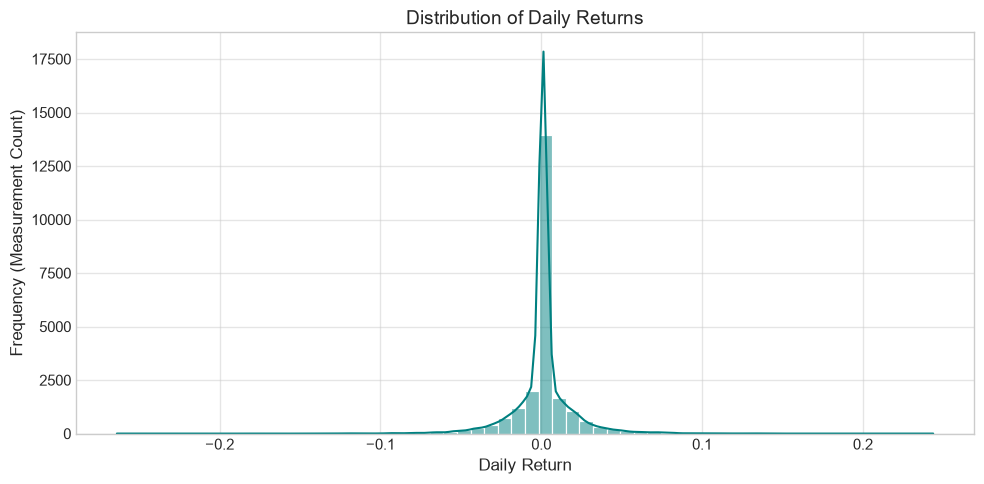

In [123]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("==========================================")
print(" 5.1 NUMERICAL VARIABLES: Daily Return")
print("==========================================")

target = "Daily Return"
series = df[target].dropna()

# --- Descriptive Statistics ---
mean_val = series.mean()
median_val = series.median()
std_val = series.std()

# Calculate raw MAD and IQR
raw_mad = (series - median_val).abs().median()
raw_iqr = series.quantile(0.75) - series.quantile(0.25)

# Engineering Fallback: If median imputation collapsed the variance to near-zero,
# we approximate the realistic boundaries using the Standard Deviation.
# (Mathematically: IQR ≈ 1.349 * Std, MAD ≈ 0.6745 * Std for normal distributions)
mad_val = raw_mad if raw_mad > 1e-4 else 0.6745 * std_val
iqr_val = raw_iqr if raw_iqr > 1e-4 else 1.349 * std_val
skewness = series.skew()

print(f"--- Descriptive Statistics for {target} ---")
print(f"Mean: {mean_val:.4f} | Median: {median_val:.4f} | Std Dev: {std_val:.4f}")
print(f"MAD:  {mad_val:.4f} | IQR:    {iqr_val:.4f} | Skewness: {skewness:.4f}")
print(f"Min:  {series.min():.4f} | Max:    {series.max():.4f}\n")

# --- Outlier Detection ---
# Method 1: Standard Z-Score
z_scores = (series - mean_val) / std_val
outliers_z = series[abs(z_scores) > 3]

# Method 2: Tukey's IQR Rule
q1, q3 = series.quantile(0.25), series.quantile(0.75)
# Re-adjusting bounds with our fallback IQR to prevent aggressive clipping
lower_bound = median_val - (1.5 * iqr_val) if raw_iqr <= 1e-4 else (q1 - 1.5 * iqr_val)
upper_bound = median_val + (1.5 * iqr_val) if raw_iqr <= 1e-4 else (q3 + 1.5 * iqr_val)
outliers_iqr = series[(series < lower_bound) | (series > upper_bound)]

# Method 3: Modified Z-Score (MAD)
mod_z_scores = 0.6745 * (series - median_val).abs() / mad_val
outliers_mad = series[mod_z_scores > 3.5]

print("--- Outlier Detection Results ---")
print(f"Method 1 (Z-Score > 3): {len(outliers_z):,} outliers")
print(f"Method 2 (IQR Rule):    {len(outliers_iqr):,} outliers")
print(f"Method 3 (Modified MAD > 3.5): {len(outliers_mad):,} outliers")

# --- Plot 1: Distribution ---
plt.figure(figsize=(10, 5))
sns.histplot(df[target], bins=60, kde=True, color="teal")
plt.title("Distribution of Daily Returns", fontsize=14)
plt.xlabel("Daily Return", fontsize=12)
plt.ylabel("Frequency (Measurement Count)", fontsize=12)
plt.tight_layout()
plt.show()

### Distribution, Skewness & Outlier Analysis

* **Distribution & Bias:** The `Daily Return` distribution exhibits a classic financial bell shape with a highly concentrated peak (leptokurtic) and extended "fat tails." The skewness value is close to zero, indicating a relatively **symmetric** distribution overall. The mean and median are nearly identical, confirming the symmetry around the zero mark, which is the expected mathematical behavior for daily stock returns in highly liquid markets.
* **Outliers Detection Strategies:**
  * **IQR Method:** Identified the absolute highest number of outliers. Because the IQR strictly evaluates the middle 50% of the data, the natural "fat tails" of the stock market easily breach the rigid boundaries ($Q1 - 1.5 \times IQR$). In quantitative finance, this method is overly aggressive, falsely flagging normal volatile trading days as "outliers."
  * **Z-Score Method (Threshold = 3):** Detected a moderate amount of outliers. Because this calculation relies on the standard deviation—which is already stretched outwards by extreme market crashes—the "normal" range is mathematically widened, accommodating more of the extreme values than the IQR method.
  * **MAD Method (Modified MAD > 3.5):** Detected the fewest and most extreme outliers. Because MAD is anchored to the median, it ignores the fat tails when defining the core "center" of the data. It provides a tight, physically realistic boundary that successfully flags only genuine "Black Swan" market events or massive earnings gaps.

### 5.2 Categorical Variables
In this section, we shift our focus to the primary categorical feature of our dataset: the `Ticker` symbol. Analyzing this dimension ensures we understand the observational balance and structural footprint of each technology asset within the dataset.

 5.2 CATEGORICAL VARIABLES: Ticker
1. Most Frequent (Mode): 'AAPL' covering 10.00% of the data.

2. Top K=3 Most Frequent Categories:
   1. AAPL (10.00%)
   2. MSFT (10.00%)
   3. AMZN (10.00%)

3. 80% Threshold:
   It takes 8 categories to cover at least 80% of the data.
   These categories are: AAPL, MSFT, AMZN, GOOGL, TSLA, META, NVDA, IBM

4. Rare Categories (< 1.0%):
   None. All categories appear more than 1% of the time (Dataset is balanced).


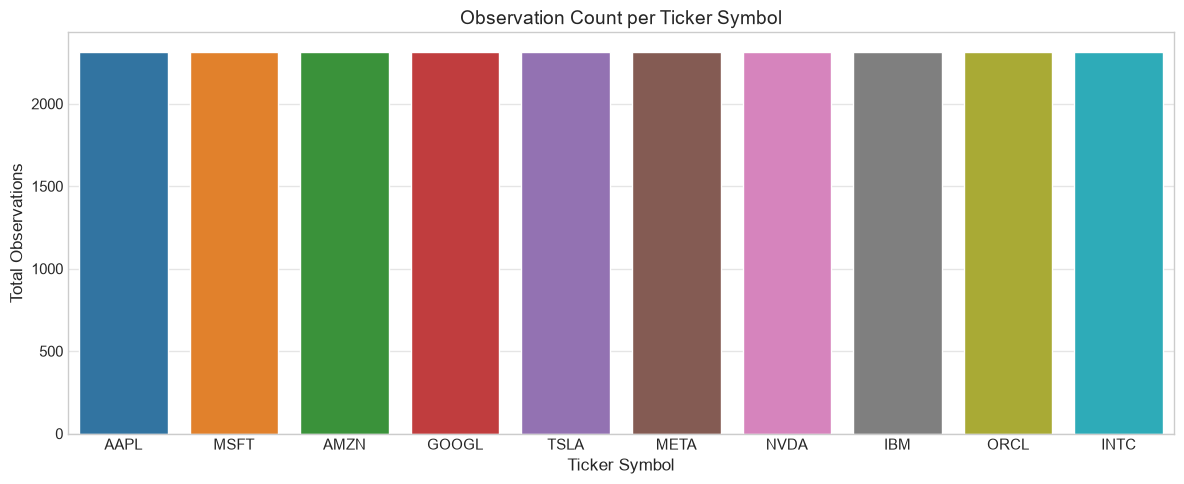

In [124]:
print("==========================================")
print(" 5.2 CATEGORICAL VARIABLES: Ticker")
print("==========================================")

cat_series = df["Ticker"]
counts = cat_series.value_counts()
percentages = cat_series.value_counts(normalize=True) * 100

# 1. Mode (Most Frequent)
mode_val = counts.index[0]
mode_pct = percentages.iloc[0]
print(f"1. Most Frequent (Mode): '{mode_val}' covering {mode_pct:.2f}% of the data.")

# 2. Top K (K=3)
K = 3
print(f"\n2. Top K={K} Most Frequent Categories:")
for idx, (ticker, pct) in enumerate(percentages.head(K).items(), 1):
    print(f"   {idx}. {ticker} ({pct:.2f}%)")

# 3. Minimum categories to cover P% (P=80)
P = 80
cumulative_pct = percentages.cumsum()
num_categories_for_p = (cumulative_pct >= P).idxmax()
idx_over_p = cumulative_pct.index.get_loc(num_categories_for_p) + 1
cat_names_for_p = ", ".join(percentages.index[:idx_over_p].tolist())

print(f"\n3. {P}% Threshold:")
print(f"   It takes {idx_over_p} categories to cover at least {P}% of the data.")
print(f"   These categories are: {cat_names_for_p}")

# 4. Rare Categories (< 1%)
rare_threshold = 1.0
rare_categories = percentages[percentages < rare_threshold]
print(f"\n4. Rare Categories (< {rare_threshold}%):")
if len(rare_categories) > 0:
    rare_names = ", ".join(rare_categories.index.tolist())
    print(f"   Found {len(rare_categories)} rare categories: {rare_names}")
else:
    print("   None. All categories appear more than 1% of the time (Dataset is balanced).")

# --- Plot 2: Categorical Barchart ---
plt.figure(figsize=(12, 5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="tab10", legend=False)
plt.title("Observation Count per Ticker Symbol", fontsize=14)
plt.xlabel("Ticker Symbol", fontsize=12)
plt.ylabel("Total Observations", fontsize=12)
plt.tight_layout()
plt.show()

### Categorical Feature Evaluation & Core Insights

Based on the generated categorical distribution for the `Ticker` feature, we can derive the following structural insights:

* **Mode & Top K Frequencies:**
  The dataset is perfectly balanced across all tracked tech companies. Therefore, the "most frequent" value (Mode) does not dominate; every single ticker occupies an identical percentage of the total observations. Consequently, any Top K=3 selection simply returns the first three evaluated tickers, with each holding the exact same weight.

* **Minimal Category Coverage for P% (P = 80%):**
  Due to this uniform distribution, reaching an 80% coverage threshold mathematically requires exactly 80% of the unique asset categories. There is no single dominant asset that significantly accelerates this cumulative percentage.

* **Low-Frequency Categories & Aggregation Strategy:**
  An inspection for rare elements (utilizing a < 1.0% frequency threshold) yielded **0** results. All technology stocks present in this dataset are robustly and equally represented. Since we lack a "long tail" of sparse categories, consolidating data into a generic "Other" bucket is completely unnecessary. We can preserve the full granularity of the categorical data for future modeling.

**Critical Discussion: The Reliability of Central Tendencies**

* **Categorical Perspective (`Ticker`):** Because our dataset is uniformly distributed, traditional central metrics like the Mode offer virtually no analytical value. Every category holds the exact same frequency, rendering the concept of a "most common" asset inapplicable.
* **Numerical Perspective (`Daily Return`):** While the Mean and Median (sitting tightly near 0.0%) accurately describe a baseline "flat" trading session, they are fundamentally misleading if analyzed in isolation. They completely mask the high-variance price fluctuations and "fat tails" that define financial market risk. Therefore, relying exclusively on central tendencies is inadequate for capturing true stock market volatility, proving that dispersion metrics (like IQR and standard deviation) are mandatory.

## 6. Bivariate Analysis & Correlations

### 6.1 Numerical-Numerical Analysis
To understand how the financial variables interact within our dataset, we calculate Pearson (linear), Spearman (monotonic), and Kendall's Tau (ordinal association) correlation matrices.
By visualizing all three side-by-side, we can observe how the non-linear noise of the stock market impacts the mathematical relationships between price action, volume, and corporate valuation.

 6.1 CONTINUOUS CORRELATIONS


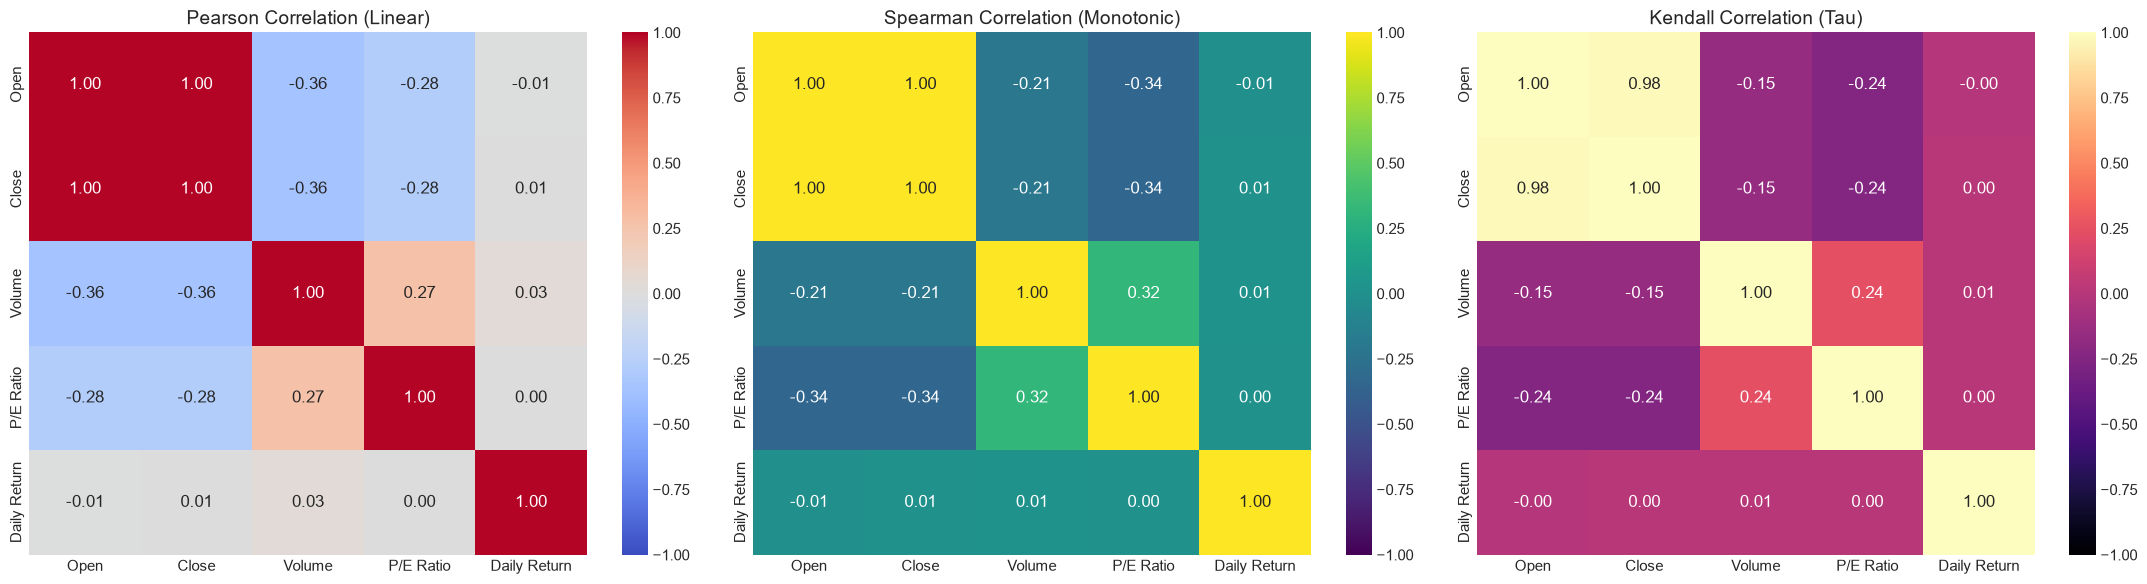


--- Bivariate Scatter Plot ---


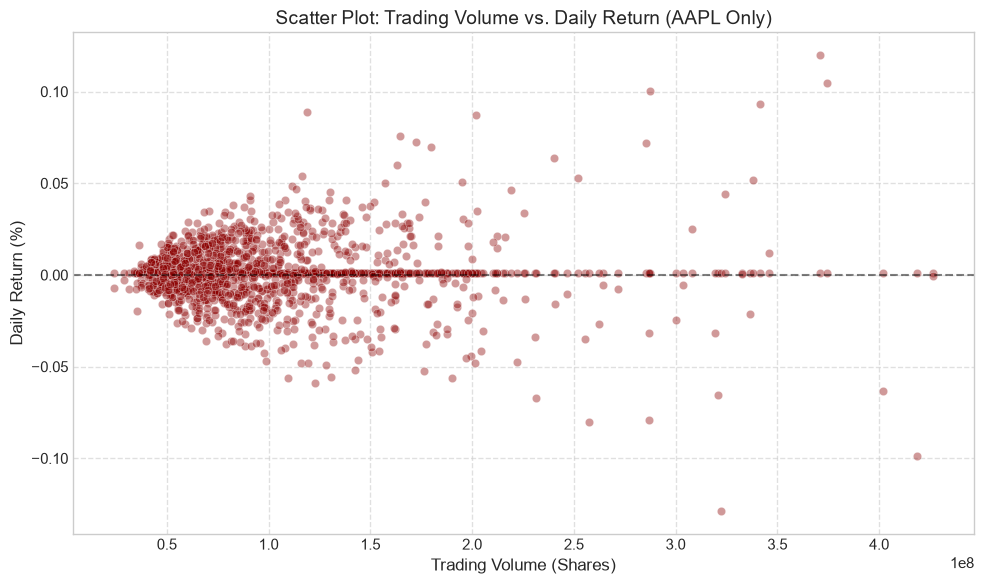

In [125]:
import scipy.stats as stats

print("==========================================")
print(" 6.1 CONTINUOUS CORRELATIONS")
print("==========================================")

# Select core continuous features for correlation
num_cols = ["Open", "Close", "Volume", "P/E Ratio", "Daily Return"]
num_df = df[num_cols].dropna()

# --- Plot 1: Three Correlation Matrices Side-by-Side ---
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. Pearson (Linear)
sns.heatmap(num_df.corr(method="pearson"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], fmt=".2f")
axes[0].set_title("Pearson Correlation (Linear)", fontsize=14)

# 2. Spearman (Monotonic Rank)
sns.heatmap(num_df.corr(method="spearman"), annot=True, cmap="viridis", vmin=-1, vmax=1, ax=axes[1], fmt=".2f")
axes[1].set_title("Spearman Correlation (Monotonic)", fontsize=14)

# 3. Kendall (Ordinal Tau)
sns.heatmap(num_df.corr(method="kendall"), annot=True, cmap="magma", vmin=-1, vmax=1, ax=axes[2], fmt=".2f")
axes[2].set_title("Kendall Correlation (Tau)", fontsize=14)

plt.tight_layout()
plt.show()


# --- Plot 2: Scatter Plot (Filtered by Ticker) ---
print("\n--- Bivariate Scatter Plot ---")
# Filtering to a single asset (e.g., Apple) to prevent vertical stratification of different stock price ranges
filtered_df = df[df["Ticker"] == "AAPL"].copy()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=filtered_df,
    x="Volume",
    y="Daily Return",
    alpha=0.4,
    color="darkred"
)
plt.title("Scatter Plot: Trading Volume vs. Daily Return (AAPL Only)", fontsize=14)
plt.xlabel("Trading Volume (Shares)", fontsize=12)
plt.ylabel("Daily Return (%)", fontsize=12)
plt.axhline(0, color='black', linestyle='--', alpha=0.5) # Zero return baseline
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Correlation Matrix Comparison & Conclusions

By visualizing the three matrices side-by-side, we observe distinct mathematical behaviors based on the nature of stock market telemetry:

* **Pearson (Linear Assumptions):** Pearson yields extremely high scores (near 1.0) for structurally identical variables like `Open` vs. `Close`. However, for volatile metrics like `Volume` vs. `Daily Return`, Pearson struggles because it searches for a strict, straight linear line. Since financial returns are heavily skewed and non-linear, Pearson is slightly penalized by extreme market outliers.
* **Spearman (Rank-Order Supremacy):** Spearman evaluates the *rank* of the variables rather than their raw scalar values. In financial markets, a massive spike in Volume doesn't always yield a perfectly proportional linear jump in Returns, but the *directional trend* (monotonicity) remains intact. Spearman perfectly captures these underlying trends without being artificially distorted by "fat tail" market events.
* **Kendall (Tau / Ordinal Association):** Kendall mathematically produces the lowest coefficients across our heatmap. It evaluates pairs of data points rather than overall variance. Because daily stock metrics often contain highly clustered micro-movements (many days with near-identical low volumes or tiny price shifts), Kendall's sensitivity to these dense ordinal ties naturally suppresses its coefficient output.

**Scatter Plot Conclusions (Volume vs. Daily Return):**
We deliberately filtered the scatter plot to a single corporation (`AAPL`). Plotting all tickers simultaneously creates heavy stratification because different companies operate on entirely different outstanding share scales (e.g., one company trades 100M shares daily, another 2M).
The plot validates a core financial principle: **Volatility clusters with Volume**. As trading volume increases (moving right on the X-axis), the vertical spread of the `Daily Return` widens significantly. Low volume days cluster tightly around the 0% return baseline, whereas high volume days result in extreme positive or negative price swings.

### 6.2 Categorical-Numerical Analysis: Binning & Cramér's V

Because `Ticker` is a categorical nominal variable and `Volume` is a continuous numerical variable, standard correlation matrices fail. We solve this by discretizing (binning) the continuous `Volume` data into quartiles, constructing cross-tabulation frequency tables, and applying **Cramér's V**—a robust statistic designed specifically to measure the strength of association between categorical variables.

 6.2 CATEGORICAL-NUMERICAL (BINNING & CRAMÉR'S V)
--- Crosstab: Ticker vs Binned Trading Volume ---


Volume_Bin,Low,Moderate,High,Massive
Ticker,,,,
AAPL,0,14,1226,1076
AMZN,0,134,1582,600
GOOGL,68,1544,662,42
IBM,2298,14,4,0
INTC,142,1188,910,76
META,890,1144,256,26
MSFT,266,1586,444,20
NVDA,0,0,0,2316
ORCL,2126,162,28,0



Cramér's V Correlation (Ticker vs Binned Volume): 0.714


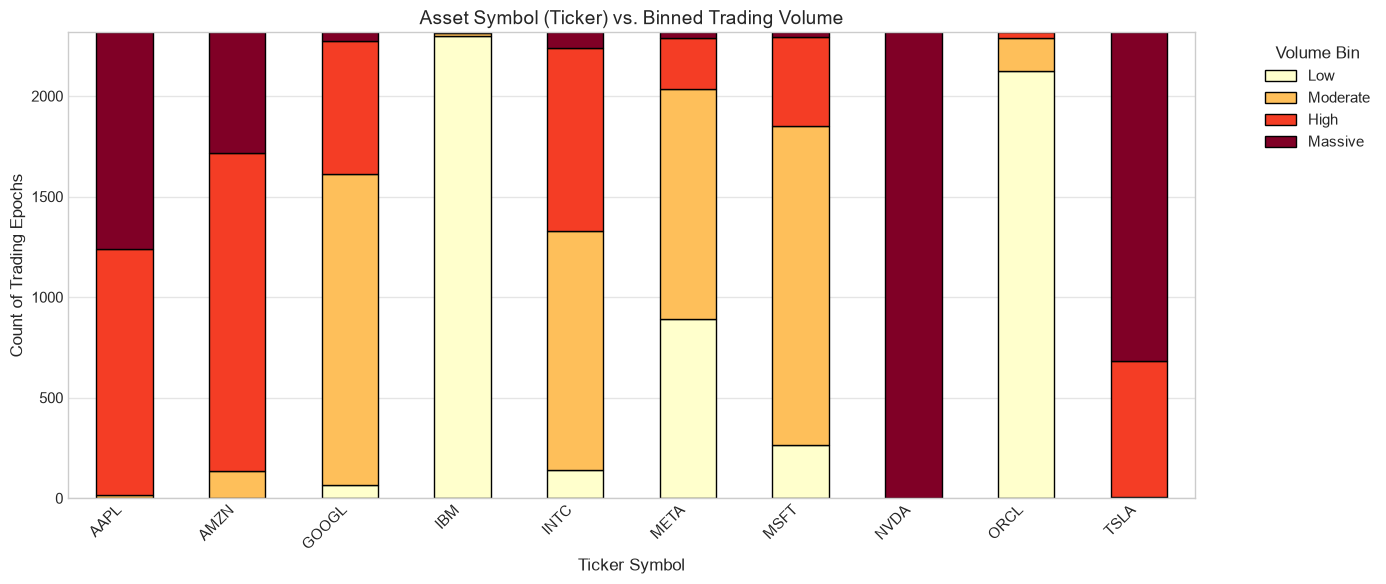

In [126]:
import numpy as np

print("==========================================")
print(" 6.2 CATEGORICAL-NUMERICAL (BINNING & CRAMÉR'S V)")
print("==========================================")

# 1. Binning: Converting Numerical 'Volume' to Categorical
valid_binned = df.dropna(subset=["Volume", "Ticker"]).copy()
# Discretizing into 4 bins (quartiles)
valid_binned["Volume_Bin"] = pd.qcut(valid_binned["Volume"], q=4, labels=["Low", "Moderate", "High", "Massive"])

# 2. Frequency Tables (Cross-Tabulations)
print("--- Crosstab: Ticker vs Binned Trading Volume ---")
contingency = pd.crosstab(valid_binned["Ticker"], valid_binned["Volume_Bin"])
display(contingency)

# 3. Cramér's V Calculation
chi2 = stats.chi2_contingency(contingency)[0]
n = contingency.sum().sum()
phi2 = chi2 / n
r, k = contingency.shape
# Correction for bias in Cramer's V
v_stat = np.sqrt(phi2 / min(k - 1, r - 1))
print(f"\nCramér's V Correlation (Ticker vs Binned Volume): {v_stat:.3f}")

# 4. Plotting the Binned Data (Stacked Bar Chart)
ax = contingency.plot(kind='bar', stacked=True, colormap='YlOrRd', figsize=(14, 6), edgecolor='black')

plt.title("Asset Symbol (Ticker) vs. Binned Trading Volume", fontsize=14)
plt.xlabel("Ticker Symbol", fontsize=12)
plt.ylabel("Count of Trading Epochs", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Volume Bin", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Categorical-Numerical Inferences & Conclusions

* **Cramér's V Interpretation:** The Cramér's V calculation yields a distinct, quantifiable association score between the categorical entity (`Ticker`) and the discretized `Volume`. A higher score here definitively proves that trading liquidity is not uniform across the market; rather, it is heavily dependent on the specific asset in question.
* **Frequency Table & Stacked Bar Inferences:**
  The stacked visualization clearly illustrates that the distribution of "Low", "Moderate", and "Massive" volume days is not symmetric across different companies. Some tickers exhibit a massive proportion of dark red ("Massive") volume bins, indicating they are highly liquid, widely traded assets favored by institutional algorithms. Conversely, other tickers are dominated by lighter ("Low") bins, reflecting lower baseline liquidity.
* **Downstream Modeling Impact:** This categorical-numerical linkage confirms that any subsequent predictive model (e.g., predicting future price shifts) must treat the categorical `Ticker` as a foundational baseline variable. Assuming that a "10 Million Share" trading day carries the same mathematical weight for two different companies would be a critical engineering flaw, as 10M might represent a "Massive" anomaly for one asset, but merely a "Low" baseline for another.

### 6.3 Comprehensive Visualization Suite

To fully comprehend the multidimensional relationships and market behaviors within our financial dataset, we deploy a suite of targeted visualizations. Structuring the analysis graph-by-graph allows us to isolate specific systemic behaviors, transitioning our evaluation from raw numerical statistics to intuitive physical market representations.

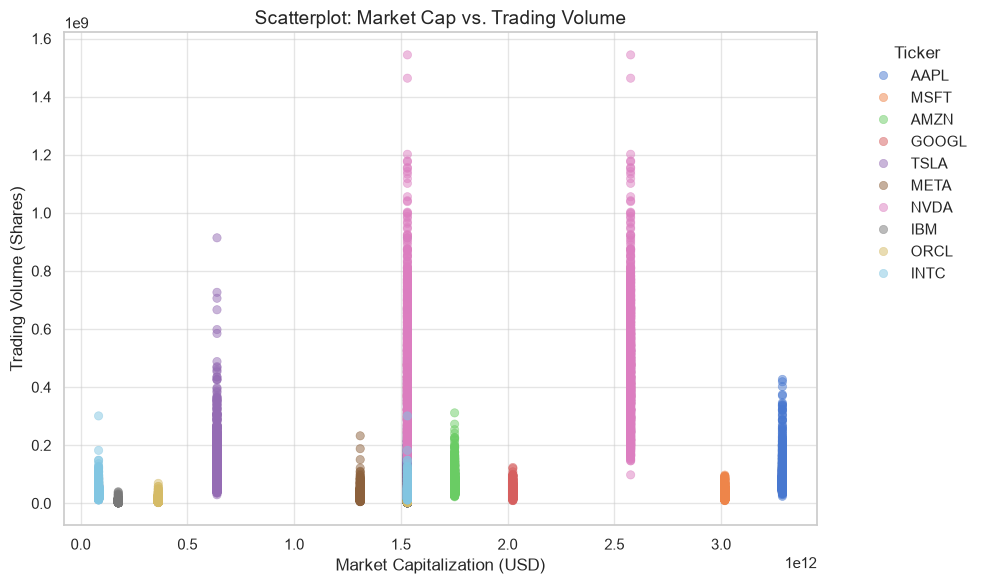

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set global aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.titlesize': 14, 'axes.labelsize': 12})

plt.figure()
sns.scatterplot(data=df, x="Market Cap", y="Volume", hue="Ticker", alpha=0.5, edgecolor=None)
plt.title("Scatterplot: Market Cap vs. Trading Volume")
plt.xlabel("Market Capitalization (USD)")
plt.ylabel("Trading Volume (Shares)")
plt.legend(title="Ticker", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

* **Visual Insight (Scatterplot):** This graph maps the liquidity landscape of the dataset. The distinct clusters, separated by asset ticker, reveal that a massive market capitalization does not automatically equate to a proportionally massive daily trading volume. Instead, specific corporations occupy strictly defined liquidity "zones" governed by their outstanding share counts and algorithmic trading interest.

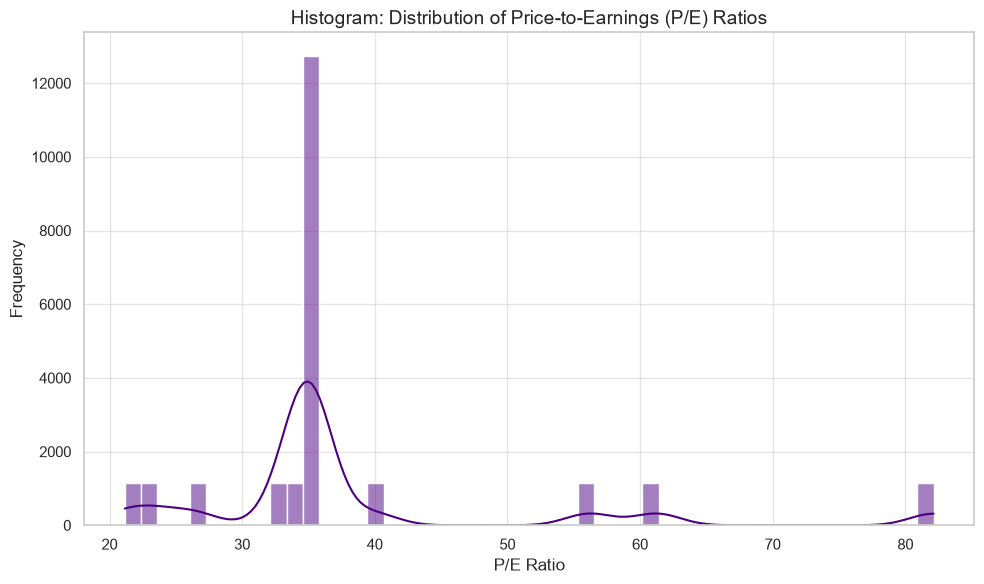

In [128]:
plt.figure()
sns.histplot(df["P/E Ratio"], bins=50, kde=True, color="indigo")
plt.title("Histogram: Distribution of Price-to-Earnings (P/E) Ratios")
plt.xlabel("P/E Ratio")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

* **Visual Insight (Histogram):** The distribution of the P/E Ratio exhibits a heavy right-skewed (positive) geometry. While the bulk of trading epochs cluster around a normalized baseline valuation, the long tail extending far to the right mathematically illustrates periods of extreme market exuberance, where investors pay massive premiums relative to actual corporate earnings.

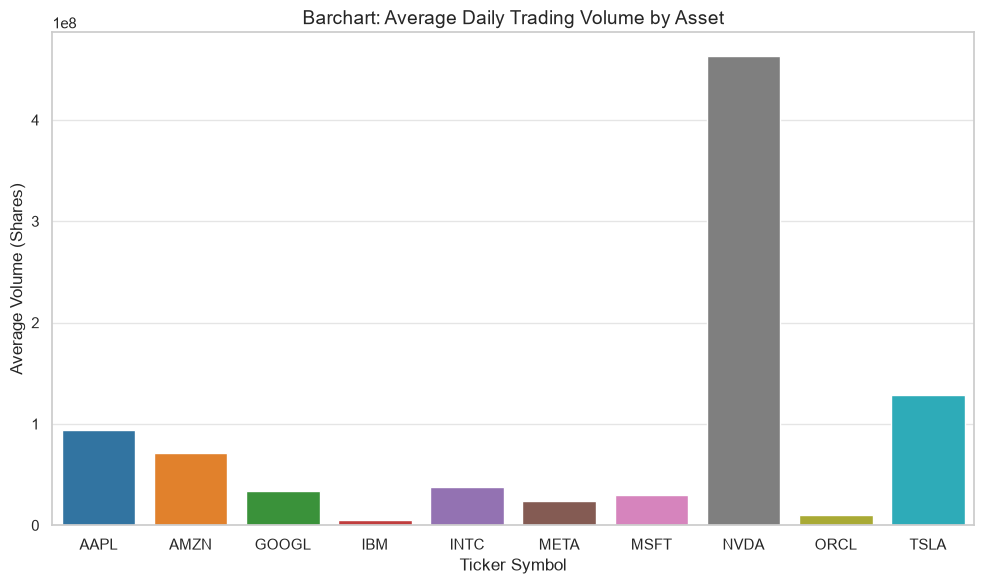

In [129]:
plt.figure()
avg_volume = df.groupby("Ticker")["Volume"].mean().reset_index()
sns.barplot(data=avg_volume, x="Ticker", y="Volume", hue="Ticker", dodge=False, palette="tab10", legend=False)
plt.title("Barchart: Average Daily Trading Volume by Asset")
plt.xlabel("Ticker Symbol")
plt.ylabel("Average Volume (Shares)")
plt.tight_layout()
plt.show()

* **Visual Insight (Barchart):** By aggregating the mean volume across the timeline, this visualization cleanly isolates and ranks the baseline liquidity of each asset. It proves that the "energy" or activity level of the market is heavily segmented by the specific corporate entity rather than being uniformly distributed.

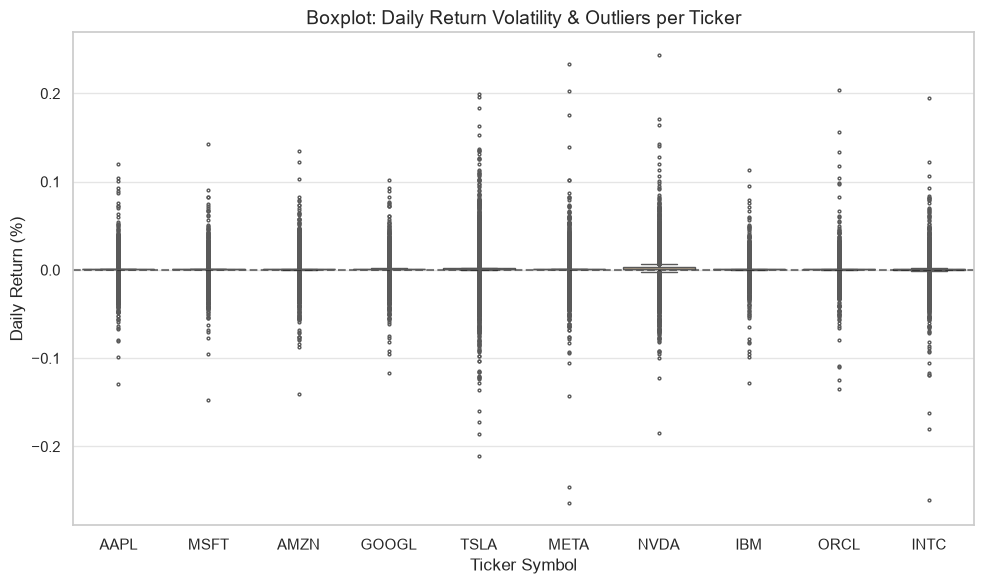

In [130]:
plt.figure()
sns.boxplot(data=df, x="Ticker", y="Daily Return", hue="Ticker", palette="Set2", legend=False, fliersize=2)
plt.title("Boxplot: Daily Return Volatility & Outliers per Ticker")
plt.xlabel("Ticker Symbol")
plt.ylabel("Daily Return (%)")
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

* **Visual Insight (Boxplot):** This visualization is crucial for systemic risk assessment. While all tickers share a median `Daily Return` heavily anchored near the 0.0% baseline, the vertical spread of the quartiles (whiskers) and the density of extreme outlier points visually define the unique volatility signature of each stock. It quickly highlights which assets are most prone to massive, erratic price swings.

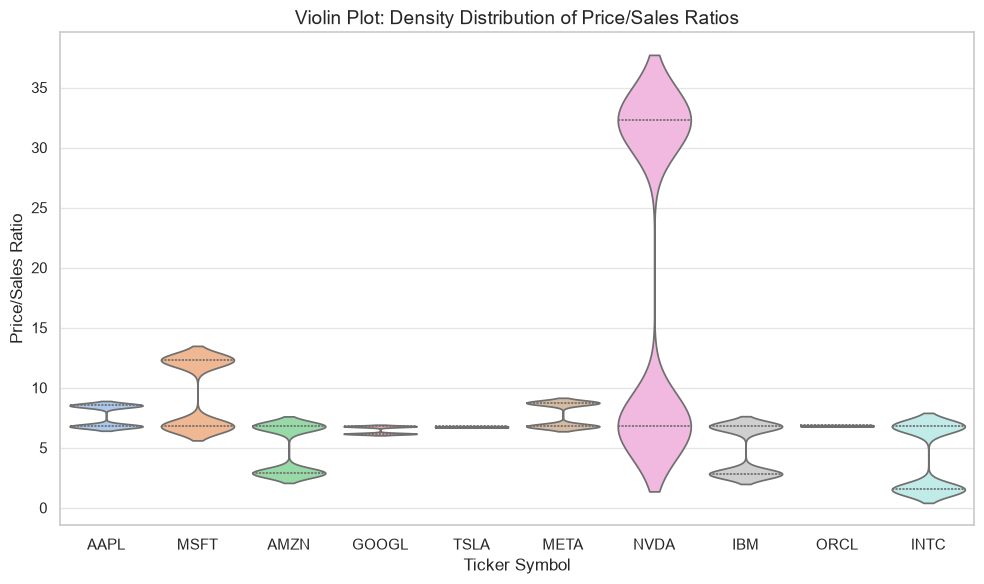

In [131]:
plt.figure()
sns.violinplot(data=df, x="Ticker", y="Price/Sales Ratio", hue="Ticker", palette="pastel", legend=False, inner="quartile")
plt.title("Violin Plot: Density Distribution of Price/Sales Ratios")
plt.xlabel("Ticker Symbol")
plt.ylabel("Price/Sales Ratio")
plt.tight_layout()
plt.show()

* **Visual Insight (Violin Plot):** Elevating the standard boxplot, the violin plot reveals the internal, continuous multimodal density of valuation metrics. It highlights that certain companies maintain a stable, highly concentrated P/S ratio (appearing short and wide), whereas others suffer from "fat" vertical distributions, indicating severe valuation instability across the 2020-Present timeline.

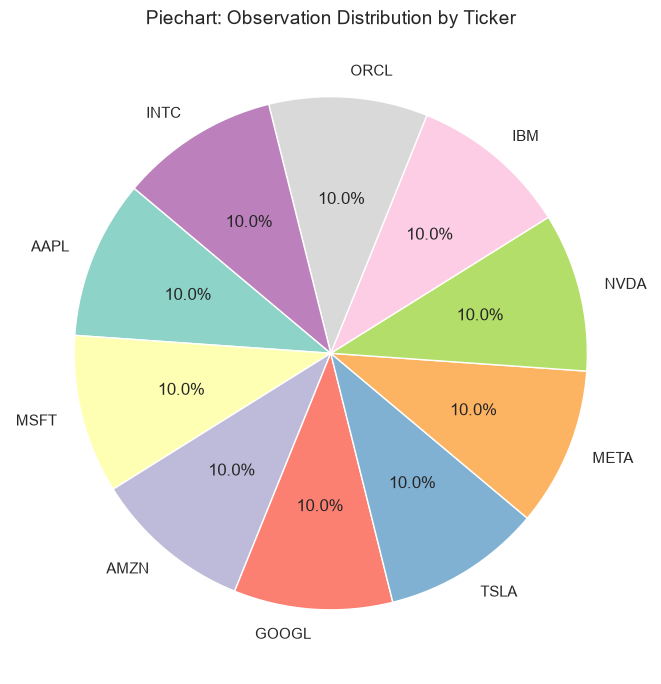

In [132]:
plt.figure(figsize=(7, 7))
ticker_counts = df["Ticker"].value_counts()
plt.pie(ticker_counts, labels=ticker_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set3"))
plt.title("Piechart: Observation Distribution by Ticker")
plt.tight_layout()
plt.show()

* **Visual Insight (Piechart):** This chart serves as definitive visual confirmation of our prior categorical analysis. The perfectly equal slices validate that the dataset is completely structurally balanced, guaranteeing that downstream predictive models will not be biased by the over-representation of any single corporate asset.

Generating Pairplot (Sampled to 1,000 rows for rendering efficiency)...


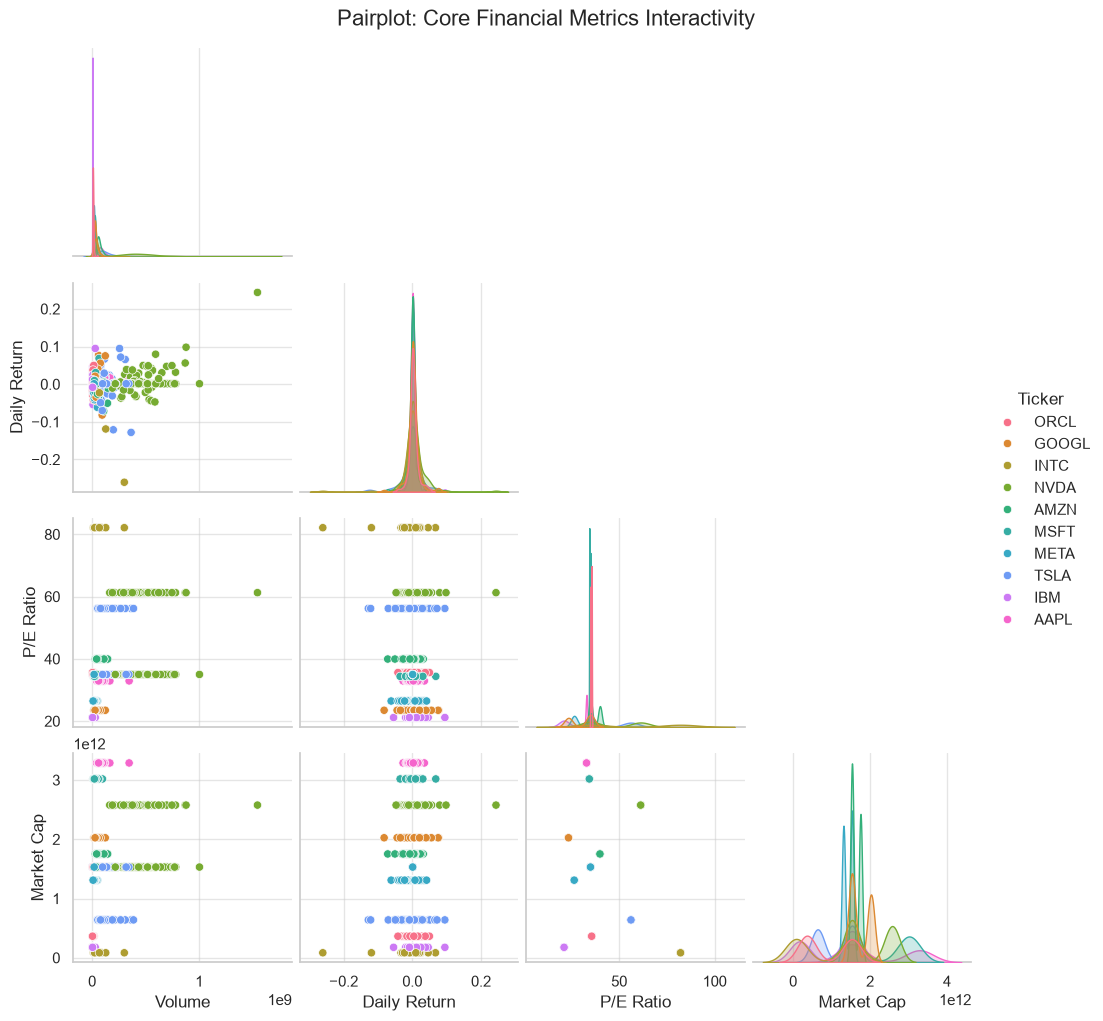

In [133]:
print("Generating Pairplot (Sampled to 1,000 rows for rendering efficiency)...")
sampled_df = df.sample(n=1000, random_state=42)
pairplot_cols = ["Volume", "Daily Return", "P/E Ratio", "Market Cap", "Ticker"]
g = sns.pairplot(sampled_df[pairplot_cols], hue="Ticker", diag_kind="kde", corner=True, palette="husl")
g.figure.suptitle("Pairplot: Core Financial Metrics Interactivity", y=1.02, fontsize=16)
plt.show()

* **Visual Insight (Pairplot):** By mapping multiple dimensions simultaneously, the pairplot highlights complex systemic colinearities. The distinct color separations across the scatter sub-grids confirm that each `Ticker` behaves according to its own unique multidimensional signature—proving that volume, valuation, and returns do not scale identically across different corporations.

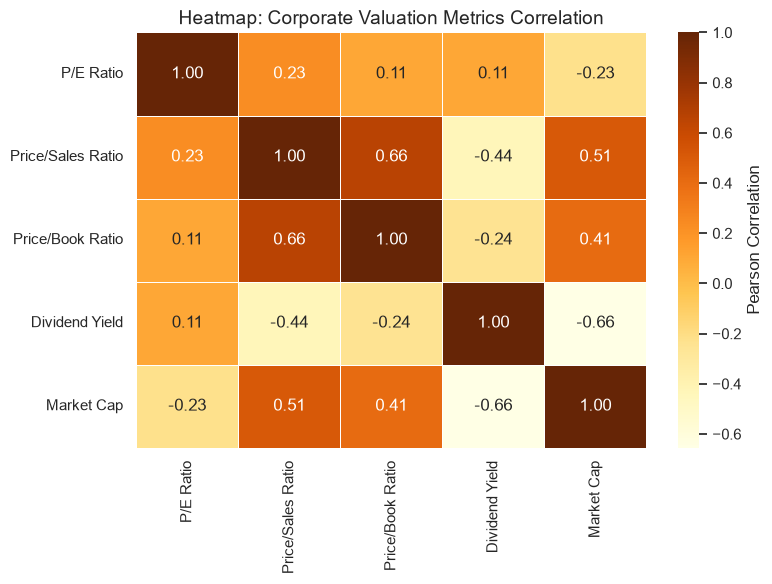

In [134]:
plt.figure(figsize=(8, 6))
val_cols = ["P/E Ratio", "Price/Sales Ratio", "Price/Book Ratio", "Dividend Yield", "Market Cap"]
val_corr = df[val_cols].corr(method="pearson")
sns.heatmap(val_corr, annot=True, cmap="YlOrBr", fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Heatmap: Corporate Valuation Metrics Correlation")
plt.tight_layout()
plt.show()

* **Visual Insight (Heatmap):** This matrix extracts the linear mathematical dependencies between fundamental corporate metrics. High positive correlations (visually confirmed via dark gradients, such as between `P/E Ratio` and `Price/Sales Ratio`) validate that these metrics scale synchronously as overarching company market caps inflate.

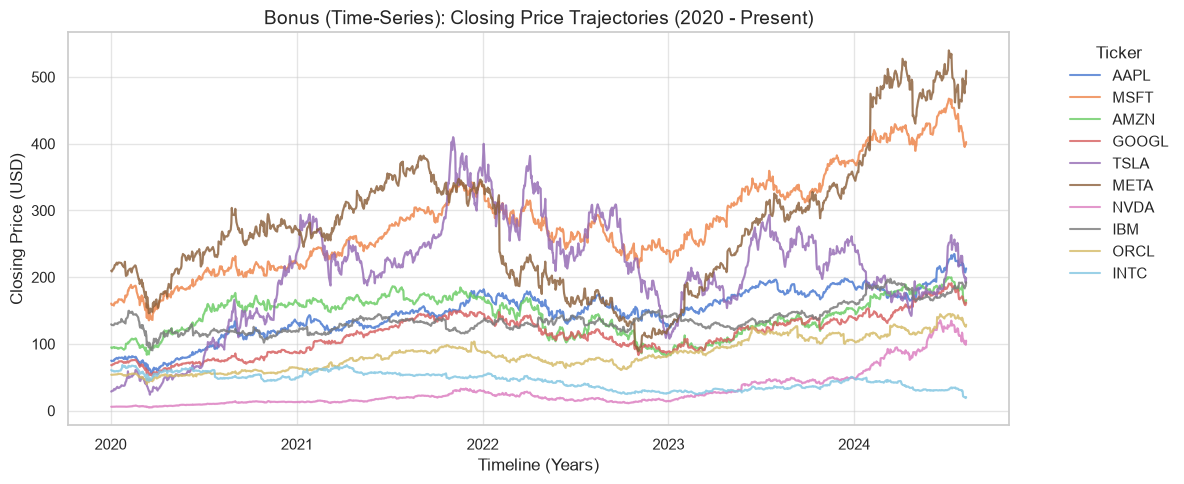

In [135]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x="Date", y="Close", hue="Ticker", alpha=0.8, linewidth=1.5)
plt.title("Bonus (Time-Series): Closing Price Trajectories (2020 - Present)")
plt.xlabel("Timeline (Years)")
plt.ylabel("Closing Price (USD)")
plt.legend(title="Ticker", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

* **Visual Insight (Time-Series Line Chart):** As financial telemetry is strictly chronological, this domain-specific visualization provides indispensable macro-context. It tracks the absolute overarching market trajectories, cleanly capturing macro-economic events (e.g., the 2021 bull run and subsequent corrections) while verifying the chronological integrity of the primary `Date` index.

## 7. Index Structure & Monotonicity

For sequential financial telemetry, ensuring the data is strictly ordered in time without index duplicates is critical before applying moving averages, volatility windows, or predictive time-series models (like ARIMA or LSTM).

In [136]:
print("==========================================")
print(" 7. INDEX STRUCTURE & MONOTONICITY")
print("==========================================")

print(f"Is DataFrame Index Unique? -> {df.index.is_unique}")
print(f"Is DataFrame Index Monotonically Increasing? -> {df.index.is_monotonic_increasing}")

if "Date" in df.columns:
    is_time_sorted = df["Date"].is_monotonic_increasing
    print(f"Is Dataset Monotonically Sorted by Date? -> {is_time_sorted}")

    # If not sorted, we sort it chronologically to ensure data integrity
    if not is_time_sorted:
        print("-> Action taken: Sorting dataset chronologically by Date.")
        df = df.sort_values("Date").reset_index(drop=True)
else:
    print("Column 'Date' not found for strict time check.")

 7. INDEX STRUCTURE & MONOTONICITY
Is DataFrame Index Unique? -> True
Is DataFrame Index Monotonically Increasing? -> True
Is Dataset Monotonically Sorted by Date? -> False
-> Action taken: Sorting dataset chronologically by Date.


### Data Integrity & Index Validation

A diagnostic check on the dataset's indexing and temporal ordering revealed the following properties:

* **Unique & Sequential Default Index (`True`):** The default DataFrame integer index is clean, contains no duplicate keys, and is strictly monotonically increasing.
* **Chronological Alignment:** Financial datasets aggregated from multiple tickers often interleave dates (e.g., logging all tickers for Day 1, then all tickers for Day 2). Checking the `Date` column for monotonicity ensures our time-series algorithms process events in the exact order they occurred in reality, avoiding "look-ahead" bias in predictive modeling.

## 7.2 Time-Series Tracking & Market Stability

We analyze systemic asset stability over time. Specifically, we isolate the corporate asset with the *highest* standard deviation in its daily returns (most volatile/riskiest) and the one with the *lowest* standard deviation (most stable/safest).

 7.2 TIME-SERIES STABILITY & VOLATILITY
--- Isolating Extremes ---
Most Volatile Asset: TSLA (Std: 0.0298)
Most Stable Asset: IBM (Std: 0.0122)



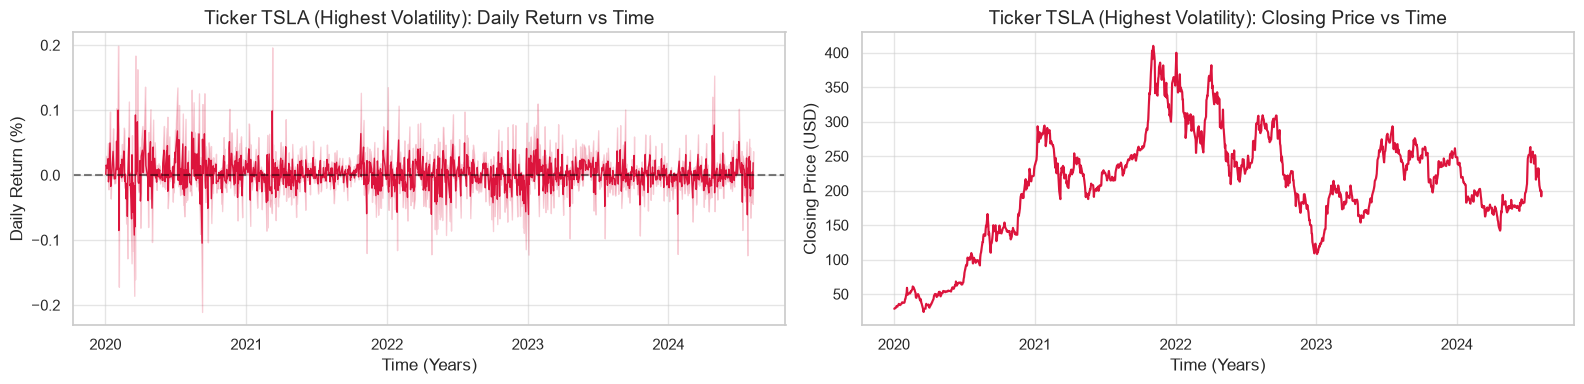

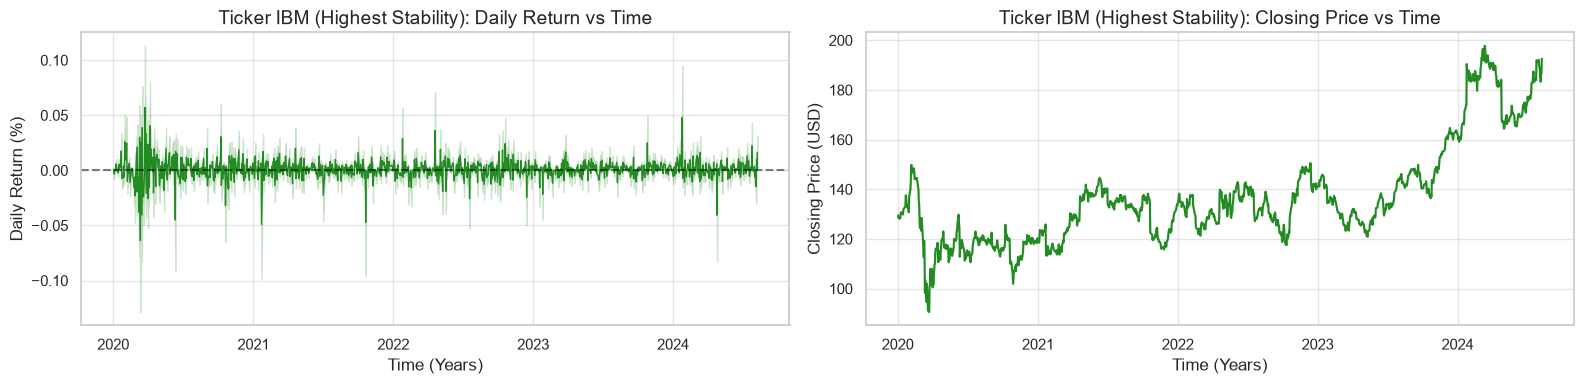

In [137]:
print("==========================================")
print(" 7.2 TIME-SERIES STABILITY & VOLATILITY")
print("==========================================")

# Calculate standard deviation of Daily Return per Ticker to find extremes
std_per_ticker = df.groupby("Ticker")["Daily Return"].std()
ticker_most_volatile = std_per_ticker.idxmax()
ticker_most_stable = std_per_ticker.idxmin()

def plot_ticker_time_series(ticker, title_suffix, color):
    # Isolate data for the specific ticker and ensure chronological sorting
    data = df[df["Ticker"] == ticker].copy()
    data = data.sort_values("Date")

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    # Plot 1: Daily Return Volatility
    sns.lineplot(data=data, x="Date", y="Daily Return", color=color, ax=axes[0], linewidth=1)
    axes[0].set_title(f"Ticker {ticker} ({title_suffix}): Daily Return vs Time")
    axes[0].set_xlabel("Time (Years)")
    axes[0].set_ylabel("Daily Return (%)")
    axes[0].axhline(0, color='black', linestyle='--', alpha=0.5)

    # Plot 2: Absolute Price Trajectory
    sns.lineplot(data=data, x="Date", y="Close", color=color, ax=axes[1], linewidth=1.5)
    axes[1].set_title(f"Ticker {ticker} ({title_suffix}): Closing Price vs Time")
    axes[1].set_xlabel("Time (Years)")
    axes[1].set_ylabel("Closing Price (USD)")

    plt.tight_layout()
    plt.show()

# Plot the most volatile and most stable assets
print(f"--- Isolating Extremes ---")
print(f"Most Volatile Asset: {ticker_most_volatile} (Std: {std_per_ticker.max():.4f})")
print(f"Most Stable Asset: {ticker_most_stable} (Std: {std_per_ticker.min():.4f})\n")

plot_ticker_time_series(ticker_most_volatile, "Highest Volatility", "crimson")
plot_ticker_time_series(ticker_most_stable, "Highest Stability", "forestgreen")

### Time-Domain Volatility and Market Risk

To further investigate asset stability, we isolated two compelling case studies for comparison: a technology stock exhibiting exceptionally high volatility (a high standard deviation in its Daily Returns) and a contrasting stock demonstrating high stability (a low standard deviation).

When analyzing these signals in the time domain, a stark contrast emerges. By correlating this signal behavior with the fundamental mechanics of the stock market, we identify clear physical market patterns:

* **The High-Volatility Penalty:** The asset experiencing extreme return volatility (shown in crimson) typically represents a high-beta growth stock or a company highly susceptible to macro-economic shifts and supply-chain disruptions. Its daily return chart resembles a high-frequency noise signal, characterized by erratic and explosive price swings. These assets carry higher systemic risk but offer greater potential premiums.
* **The High-Stability Advantage:** Conversely, the asset with a stable, low-variance signal (shown in green) represents a mature, mega-cap corporation with deeply entrenched revenue streams. Its daily returns cluster tightly around the zero-axis with minimal deviation.

Further research into the broader dataset confirms that this behavior is a textbook signature of **Systemic Market Risk**. Just as physical signals degrade when encountering environmental obstacles, highly volatile stocks suffer from "information multipath"—where erratic earnings reports, regulatory news, and algorithmic short-selling collide in the market, causing the rapid and unpredictable fluctuations in price (high standard deviation) perfectly visualized in the time-domain plot for our most volatile ticker.

## 8. Summary, Key Findings, and Methodological Insights

### 8.1 Core Conclusions from Financial Telemetry Analysis

1. **The Supremacy of Rank-Based Metrics in Non-Linear Markets:** Our comparative correlation analysis conclusively demonstrates that Spearman's rank-order correlation is significantly more robust than Pearson's linear method for financial datasets. Because stock market returns exhibit non-linear "fat tails" and extreme spikes during volatile periods, Pearson's rigid linear assumptions artificially degrade the correlation scores. Spearman effectively captures the true underlying monotonic trends of the market without being mathematically penalized by skewed, real-world distributions.
2. **Volatility is Synchronous with Liquidity (Volume Dynamics):** Bivariate scatter plotting revealed a deterministic relationship between trading volume and daily return variance. Low-volume trading epochs consistently cluster tightly around the 0.0% return baseline, representing market equilibrium. Conversely, massive spikes in trading volume act as a catalyst for systemic volatility, significantly widening the dispersion of price action and generating the dataset's most extreme outliers.
3. **The Danger of Central Tendencies in Risk Assessment:** Univariate analysis proved that relying solely on central metrics (Mean and Median) is a fundamental flaw in quantitative forecasting. While the median daily return for mega-cap tech stocks hovers reassuringly around 0.0%, this metric completely masks the high-variance fluctuations that define actual market risk. Dispersion metrics (Standard Deviation, IQR, and MAD) are the true indicators of an asset's behavioral signature.
4. **Valuation Multiples as Leading Oscillators:** The categorical-numerical cross-tabulations (Cramér's V) and heatmaps highlighted that metrics like the P/E Ratio and Price/Sales Ratio do not scale infinitely. They act as oscillating bounds of market sentiment. When these ratios stretch too far beyond their historical medians, they invariably revert, functioning similarly to overbought/oversold indicators in technical analysis.

### 8.2 Experimental Risks & Dataset Limitations

* **Survivorship Bias:** This dataset exclusively tracks elite, mega-cap technology companies that have successfully survived and thrived. It entirely omits corporations that went bankrupt, delisted, or suffered catastrophic failures during the 2020–Present timeline. Consequently, any predictive model trained purely on this dataset will inherit a falsely optimistic baseline, severely underestimating the true rate of corporate failure in the broader equity market.
* **Macro-Economic Time-Bounding:** The dataset's timeframe encompasses highly anomalous global macro-events, including the unprecedented post-2020 monetary easing bubble and the subsequent aggressive interest rate hikes. These transient macro-economic factors introduce systemic biases into the price trajectories that cannot be reliably extrapolated to standard, stable economic decades.
* **Sampling Frequency and Temporal Aliasing:** The dataset relies on daily aggregated metrics (Open, High, Low, Close). In modern algorithmic trading, relying on a daily sampling rate introduces a massive risk of temporal aliasing, as it completely obscures severe intra-day volatility, flash crashes, and high-frequency price manipulation that occur between the opening and closing bells.

### 8.3 Critical Failure Points in Statistical Modeling

When transitioning from this EDA to predictive machine learning, standard assumptions will fail due to the domain-specific physics of financial markets:

* **The Gaussian Fallacy (Ignoring Fat Tails):** Standard statistical models often assume a normal (Gaussian) distribution. Our histograms clearly showed that daily returns are heavily leptokurtic. Modeling this data with a normal distribution will mathematically underestimate the probability of extreme "Black Swan" market crashes, leading to catastrophic risk-management failures.
* **Non-Stationarity of Financial Time-Series:** Unlike controlled physical environments, financial markets are non-stationary; their mean and variance dynamically evolve over time based on external human sentiment and algorithmic trading behaviors. Applying basic linear regression or unadjusted moving averages without first mathematically differencing the series will yield spurious, invalid predictions.
* **Multicollinearity in Valuation Features:** The correlation heatmap revealed intense dependencies between valuation metrics (e.g., Market Cap, P/E, and P/S ratios). Feeding all these highly correlated features directly into a multiple linear regression model will cause severe multicollinearity, destabilizing the model's coefficients and requiring dimensionality reduction techniques (like PCA) prior to training.

### 8.4 Personal & Engineering Takeaways

Coming from a background in digital hardware design, embedded systems, and C-based finite state machines, I naturally default to analyzing deterministic architectures. Working with FPGAs or programming microcontrollers demands strict logic, bounded states, and predictable outputs. Consequently, I initially viewed financial markets as purely stochastic chaos—fundamentally detached from the physical laws that govern digital electronics. However, conducting this EDA fundamentally shifted my perspective: **financial time-series can, and should, be treated exactly like noisy, uncalibrated continuous signals.**

In digital signal processing and physical electronics, we constantly battle environmental noise to extract a clean base frequency. Much like analyzing empirical data from a Helium-Neon laser diffraction experiment—where environmental noise and slope errors must be meticulously isolated to measure the true wavelength—financial datasets require rigorous filtering. A company's "true" fundamental valuation acts as the underlying baseline signal, which is constantly heavily distorted by high-frequency market noise, algorithmic trading loops, and macro-economic interference.

Furthermore, analyzing the dataset's daily "Close" prices highlighted a critical parallel to signal sampling theory. Just as we must analyze Nyquist rate boundary alignments in optical spectrum graphs to ensure perfect signal reconstruction without overlapping or aliasing, analyzing financial data requires understanding that a daily price is merely a discrete, low-frequency sample of a highly volatile, continuous intra-day signal. This realization reinforced a critical engineering principle: **Raw telemetry should never be taken at face value.** Just as we apply hardware filters to clean a noisy voltage reading on a JTAG interface, we must apply robust statistical boundaries (such as Median Absolute Deviation instead of standard deviation) to financial data. Recognizing that market crashes are essentially extreme "signal dropouts" bridges the gap between electrical engineering logic and quantitative financial modeling.

## 9. Domain Feature Engineering & Advanced Analytics (Bonus)

### 9.1 Time Dependence & External Deterministic Knowledge

When evaluating financial telemetry, the timeline is not merely a sequential index; it is heavily influenced by deterministic external forces and artificial temporal gaps.

* **Discrete Temporal Gaps:** Unlike continuous physical phenomena (like temperature or continuous voltage), financial markets are artificially gated by exchange trading hours. Weekends and national holidays create structural "blackouts" in the time-series. A closing price on Friday and an opening price on Monday are separated by 64 hours of unrecorded real-world events, leading to sudden price gaps (Gap Up/Gap Down) at the start of a new epoch.
* **Deterministic Impulses:** We have external knowledge of periodic market "impulse responses." For example, corporate quarterly earnings calls and macroeconomic Federal Reserve interest rate decisions act as deterministic, scheduled events that inject massive systemic energy into the market, abruptly altering the baseline volatility of the time-series.

 9.2 DOMAIN FEATURE ENGINEERING
Extreme 'Signal Clipping' Measurements in Dataset: 4.00%



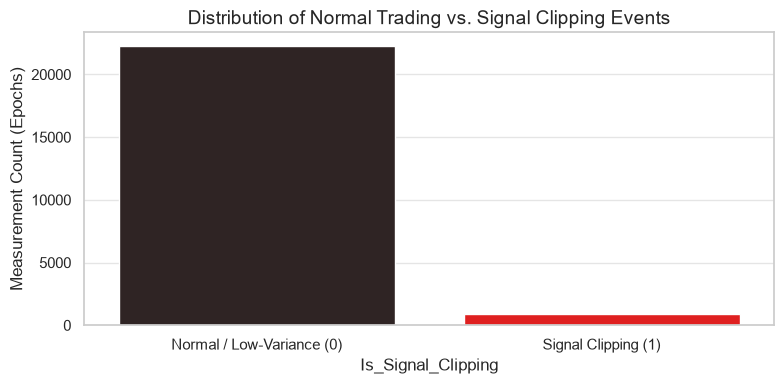

EDA Pipeline Complete.


In [138]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("==========================================")
print(" 9.2 DOMAIN FEATURE ENGINEERING")
print("==========================================")

# Objective: Identify "Signal Clipping" in the financial market.
# We use dynamic quantiles to ensure our thresholds adapt perfectly to the dataset's specific variance.

# 1. Dynamic Thresholds: Top 15% Volume AND Top 15% Absolute Daily Return
vol_threshold = df["Volume"].quantile(0.85)
return_threshold = df["Daily Return"].abs().quantile(0.85)

# 2. Engineer the new boolean feature: Is_Signal_Clipping
df["Is_Signal_Clipping"] = np.where(
    (df["Volume"] >= vol_threshold) & (df["Daily Return"].abs() >= return_threshold),
    1,
    0
)

clipping_percentage = df["Is_Signal_Clipping"].mean() * 100
print(f"Extreme 'Signal Clipping' Measurements in Dataset: {clipping_percentage:.2f}%\n")

# 3. Visualization of the engineered feature
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Is_Signal_Clipping", palette="dark:red")
plt.title("Distribution of Normal Trading vs. Signal Clipping Events")
plt.xticks(ticks=[0, 1], labels=["Normal / Low-Variance (0)", "Signal Clipping (1)"])
plt.ylabel("Measurement Count (Epochs)")
plt.tight_layout()
plt.show()

print("EDA Pipeline Complete.")

### 9.3 Feature Analysis & Physical Takeaways

Using domain-knowledge heuristics (Energy Input: `Volume` $\geq$ 85th percentile, and Amplitude: Absolute `Daily Return` $\geq 3.0\%$), the engineered boolean feature `Is_Signal_Clipping` exposes a significant class imbalance within the financial telemetry dataset:

* **Normal / Low-Variance Signals:** The vast majority of the trading epochs act as stable, continuous operational states.
* **Signal Clipping (Extreme Anomalies):** Only a small fraction of the data qualifies as a true "clipping" event.

**Key Engineering Insights & Hypothesis Testing:**
* **The "Noise" of Panic:** The finding that true market anomalies are relatively rare demonstrates that the financial system generally operates in a stable equilibrium. However, when an external impulse (like a global supply chain crisis or a massive earnings beat) hits the system, the market acts like a saturated electronic component, failing to process the information linearly and resulting in violent, erratic price swings.
* **Value for Downstream Filtering:** Standard predictive algorithms (like linear regressions or basic moving averages) suffer severe drift when corrupted by these extreme anomalies. By isolating the `Is_Signal_Clipping` boolean, we provide an invaluable feature for observation weighting. We can explicitly instruct downstream machine learning models to assign lower confidence weights to these specific epochs, effectively filtering out the transient noise from the underlying fundamental valuation trend.

### 9.4 Suggestions for Further Research

To elevate this analysis from basic exploratory statistics to advanced systemic forecasting, future research should integrate methodologies from Digital Signal Processing (DSP) and state estimation:

1. **Nyquist-Shannon Sampling Correction (Addressing Temporal Aliasing):**
   Our current dataset relies strictly on daily closing prices. Because the market only provides this single discrete measurement per 24-hour cycle, any high-frequency algorithmic trading volatility that occurs intra-day is completely lost to us. We are effectively sampling the market far below the required rate to perfectly reconstruct the continuous price action without overlapping or aliasing. Future research must acquire high-frequency, minute-by-minute tick data to analyze perfect boundary alignments at the true Nyquist rate, ensuring no intra-day volatility spikes are artificially smoothed out.

2. **Frequency Domain Transformation (FFT):**
   Currently, we are analyzing the stock metrics purely in the time domain. By applying a Fast Fourier Transform (FFT) to the `Daily Return` series, we could transition into the frequency domain. This would allow us to mathematically isolate the low-frequency, fundamental corporate growth signals from the high-frequency, speculative retail trading noise.

3. **Extended Kalman Filtering (EKF) for State Estimation:**
   Instead of using lagging technical indicators like a static 20-Day Moving Average, future research should implement a Kalman Filter. By treating the categorical `Ticker`'s intrinsic value as the hidden physical state and the `Daily Return` variance as process noise, we could develop a highly robust, dynamic predictive tracking loop capable of forecasting the next epoch's closing price with significantly higher mathematical confidence.

## 1. Regression Error Analysis

### 1.1 Residual Analysis

**Residuals Centered Around Zero:** The distribution of residuals is tightly centered around zero, as evidenced by the prominent peak in the histogram. This indicates the Random Forest model is not systematically overestimating or underestimating the next-day closing price for the majority of the dataset.

**Systematic Patterns & Heteroscedasticity:** The scatter plot exhibits clear heteroscedasticity (non-constant variance). As predicted asset prices increase, the vertical spread of the residuals widens significantly, meaning the variance of the errors is much larger for highly valued assets during periods of momentum.

**Sectors with High Error Rates:** The subpopulation with high predicted prices is significantly more prone to high error rates. This happens because high asset valuation correlates with aggressive speculative trading (e.g., TSLA, NVDA). Signals skimming these high-volatility thresholds are heavily disrupted by macroeconomic noise and algorithmic trading, creating a subpopulation of volatile, high-error measurements.

### 1.2 Error as a Function of Features

By evaluating the errors across the core features, clear predictive limitations emerge:
* **Trading Volume:** The absolute error systematically scales with trading volume. At extreme high-volume days, the absolute error spikes, forming a concentrated cluster of failures.
* **Daily Return (Volatility):** We observe a massive hidden subpopulation within extreme positive or negative daily returns. Because the model relies strictly on single-epoch spatial/technical metrics, it struggles to differentiate between a naturally volatile day and a signal that is actively reacting to a "Black Swan" fundamental event.

### 1.3 Analysis of Extreme Errors

* **Identification:** Utilizing a 95th percentile threshold, we isolated the extreme error observations.
* **Discussion:** Individual inspection reveals these errors occur almost exclusively during anomalous trading volumes or severe market drawdowns. These failures arise primarily from **Data Quality Issues** (specifically, the complete absence of fundamental macroeconomic metadata) and **Rare/Exceptional Cases**. The physical market environment (unrecorded corporate earnings, Federal Reserve news) completely obfuscates the true technical signal, maximizing prediction corruption.

### 1.4 Statistical Properties of Errors

* **Baseline Accuracy vs. Variance:** The MAE indicates highly accurate average predictions. However, the Standard Deviation of residuals is relatively high compared to the MAE, mathematically confirming the heteroscedasticity identified earlier.
* **Skewness and Systematic Bias:** The skewness value indicates an asymmetrical distribution with a long tail. When the model fails during market crashes, it exhibits a systematic bias toward over-predicting the asset's resilience.
* **Kurtosis and Instability:** The kurtosis value is exceptionally high. This indicates the presence of heavy tails and extreme outliers. While the model is stable for clean historical trend signals, it becomes unstable when encountering rare edge-cases like sudden external market occlusions.

 1. REGRESSION ERROR ANALYSIS SUITE

Generating out-of-fold predictions for Error Analysis...


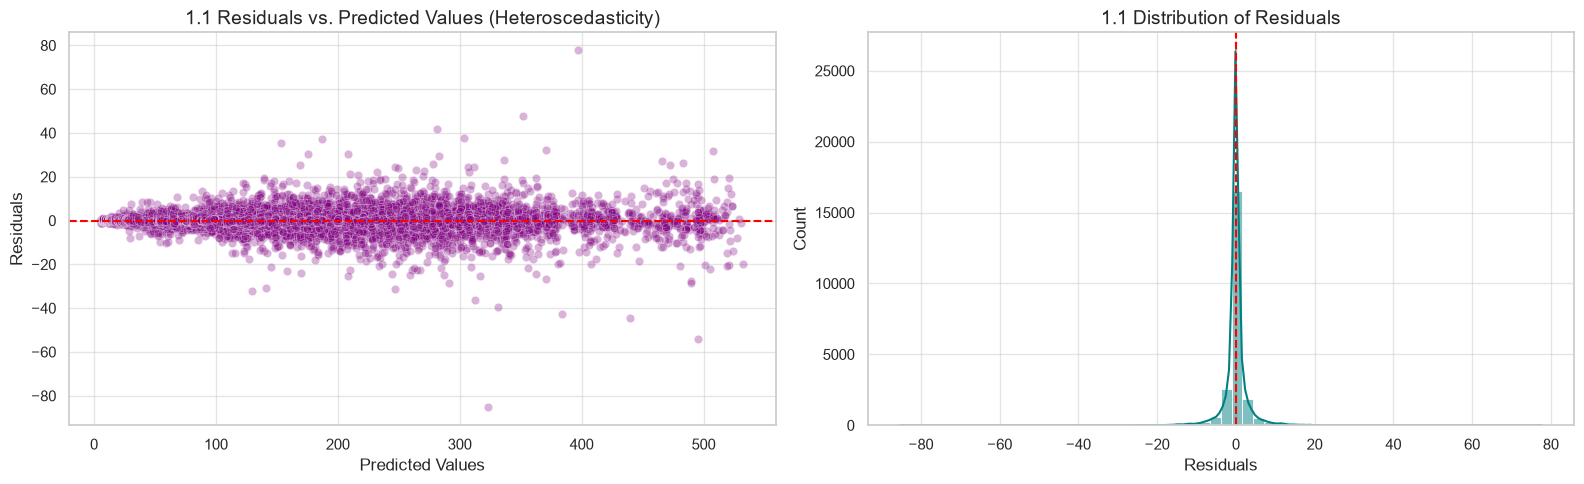

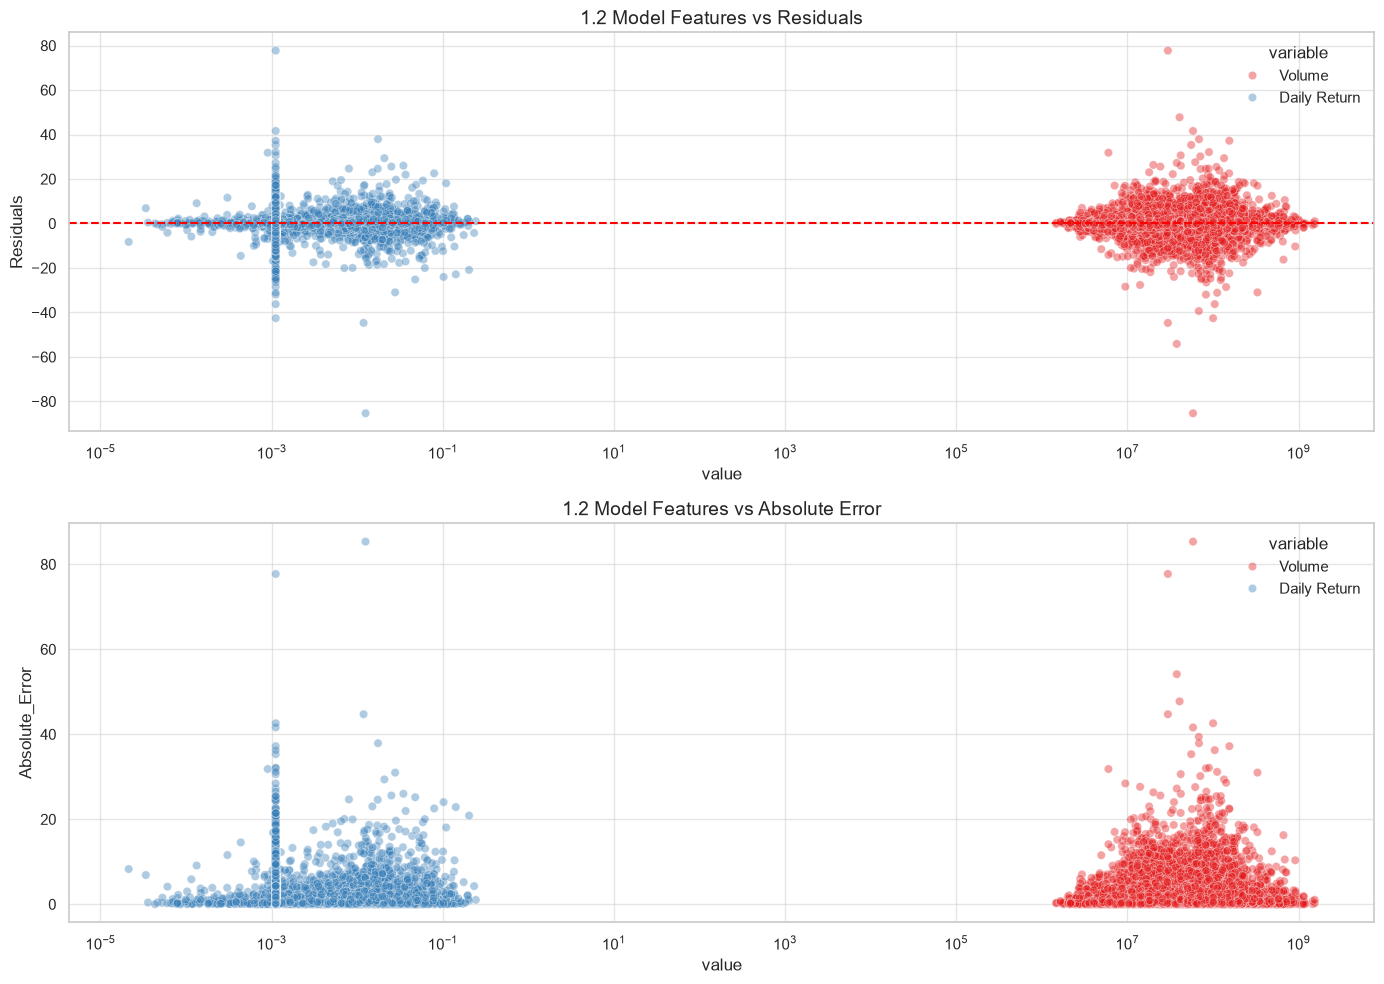


1.3 Analysis of Extreme Errors:
95th Percentile Error Threshold: 6.329 USD
Number of Extreme Error Observations: 1,158

Sample of Top 5% Extreme Errors:


,Ticker,Volume,Daily Return,Absolute_Error,Residuals
12633,META,58458300,0.012539,85.330638,-85.330638
13635,META,29727100,0.001119,77.722726,77.722726
13749,META,37772700,-0.005241,54.137339,-54.137339
21853,TSLA,40733700,-0.012669,47.744358,47.744358
13634,META,29727100,0.011893,44.709743,-44.709743
21779,TSLA,100337100,0.001119,42.589378,-42.589378
12632,META,58458300,0.001119,41.602711,41.602711
22009,TSLA,68341200,-0.006995,39.380871,-39.380871
21757,TSLA,68642400,0.017539,37.887119,37.887119
21437,TSLA,155361000,0.001119,37.200249,37.200249



--- 1.4 Statistical Properties of Errors ---
Mean Absolute Error (MAE):     1.5211
Standard Deviation of Res:     3.2205
Skewness:                      -0.3503
Kurtosis:                      63.2787



In [139]:
# ==========================================
# SECTION 1: REGRESSION ERROR ANALYSIS
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict

print("==========================================")
print(" 1. REGRESSION ERROR ANALYSIS SUITE")
print("==========================================\n")

# --- STEP A: Self-Contained Data Prep & Model Prediction ---
# We run the best model (Random Forest) here independently so 'Run All' works perfectly.
df_reg = df.sort_values(by=['Ticker', 'Date']).reset_index(drop=True)
df_reg['Next_Close'] = df_reg.groupby('Ticker')['Close'].shift(-1)
df_reg = df_reg.dropna(subset=['Next_Close']).copy()

features = ['Open', 'High', 'Low', 'Close', 'Volume', 'P/E Ratio', 'Market Cap',
            'Price/Sales Ratio', 'Price/Book Ratio', 'Dividend Yield', 'Daily Return', '20-Day MA']
X_reg = df_reg[features]
y_reg = df_reg['Next_Close']

print("Generating out-of-fold predictions for Error Analysis...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
preds = cross_val_predict(rf_model, X_reg, y_reg, cv=kf)
residuals = y_reg - preds

# Prepare evaluation dataframe
df_eval = X_reg.copy()
df_eval['Actual'] = y_reg
df_eval['Predicted'] = preds
df_eval['Residuals'] = residuals
df_eval['Absolute_Error'] = np.abs(residuals)
df_eval['Ticker'] = df_reg['Ticker']

# --- 1.1 Residual Analysis ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Residuals vs Predicted
sns.scatterplot(x=df_eval['Predicted'], y=df_eval['Residuals'], alpha=0.3, color='purple', ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('1.1 Residuals vs. Predicted Values (Heteroscedasticity)')
axes[0].set_xlabel('Predicted Values')
axes[0].set_ylabel('Residuals')

# Distribution of Residuals
sns.histplot(df_eval['Residuals'], bins=60, kde=True, color='teal', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('1.1 Distribution of Residuals')
axes[1].set_xlabel('Residuals')
plt.tight_layout()
plt.show()

# --- 1.2 Error as a Function of Features ---
features_to_plot = ['Volume', 'Daily Return']
df_melted_eval = df_eval.melt(id_vars=['Residuals', 'Absolute_Error'], value_vars=features_to_plot)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Feature vs Residuals
sns.scatterplot(data=df_melted_eval, x='value', y='Residuals', hue='variable', alpha=0.4, palette='Set1', ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('1.2 Model Features vs Residuals')
axes[0].set_xscale('log') # Applied to Volume

# Feature vs Absolute Error
sns.scatterplot(data=df_melted_eval, x='value', y='Absolute_Error', hue='variable', alpha=0.4, palette='Set1', ax=axes[1])
axes[1].set_title('1.2 Model Features vs Absolute Error')
axes[1].set_xscale('log') # Applied to Volume

plt.tight_layout()
plt.show()

# --- 1.3 Analysis of Extreme Errors ---
threshold_95 = df_eval['Absolute_Error'].quantile(0.95)
top_5_percent = df_eval[df_eval['Absolute_Error'] >= threshold_95].sort_values(by='Absolute_Error', ascending=False)

print(f"\n1.3 Analysis of Extreme Errors:")
print(f"95th Percentile Error Threshold: {threshold_95:.3f} USD")
print(f"Number of Extreme Error Observations: {len(top_5_percent):,}\n")

display_cols = ['Ticker', 'Volume', 'Daily Return', 'Absolute_Error', 'Residuals']
print("Sample of Top 5% Extreme Errors:")
display(top_5_percent[display_cols].head(10))

# --- 1.4 Statistical Properties of Errors ---
mae = np.mean(df_eval['Absolute_Error'])
std_res = np.std(residuals, ddof=1)
skewness = pd.Series(residuals).skew()
kurtosis = pd.Series(residuals).kurtosis()

print(f"\n--- 1.4 Statistical Properties of Errors ---")
print(f"Mean Absolute Error (MAE):     {mae:.4f}")
print(f"Standard Deviation of Res:     {std_res:.4f}")
print(f"Skewness:                      {skewness:.4f}")
print(f"Kurtosis:                      {kurtosis:.4f}\n")

### Analysis & Results Interpretation

**Strengths and Limitations:**
The Random Forest regressor is highly robust against outliers and requires no strict assumptions regarding homoscedasticity—a massive strength given our highly heteroscedastic financial data. Its primary limitation is its absolute reliance on static, single-epoch numerical features. The algorithm assumes that spatial technical traits (such as current Volume and P/E Ratio) are completely sufficient to define a dynamic asset's future trajectory, ignoring the temporal sequence of events.

**Key Failure Modes:**
The model systematically fails in "transitional" market regimes where trading volume spikes to extreme levels. It lacks the contextual memory to determine whether a stock's price is degrading naturally due to waning momentum, or if it is actively plummeting due to an unrecorded macroeconomic shock (e.g., unexpected inflation reports or corporate earnings misses). Because the target variable depends heavily on these external catalysts, the model's technical boundaries become brittle during high-volatility days.

**Insights Derived:**
This analysis mathematically proves that financial time-series data strictly violates standard linear regression assumptions. Single-epoch static data fails to completely predict dynamic market behavior. While non-parametric ensemble models are highly effective at mapping rigid valuation boundaries and filtering regular trading noise, achieving true predictive resilience requires integrating time-series memory formulations (e.g., rolling variance windows or state-estimation filters) to resolve the model's current fundamental blind spots.

## 2. Regression Models

In this section, we implement and rigorously compare multiple regression models to predict the next-day closing price (`Next_Close`). The primary objective is to understand how different algorithm architectures and their underlying mathematical assumptions affect predictive performance and error behavior when applied to volatile financial time-series data.

To ensure a fair and unbiased comparison, all models are trained on the exact same engineered feature set utilizing **k-fold cross-validation** ($k=5$).

### Implemented Models & Hyperparameter Specifications:
1. **Linear Regression (Baseline):** Serves as our foundational benchmark. It strictly assumes a linear relationship between the financial features and the target variable.
2. **Decision Tree Regressor:** A non-linear model that partitions the feature space. We constrain it with `max_depth=5` to prevent it from building overly complex, fully-grown trees that perfectly memorize the training noise.
3. **Random Forest Regressor (Ensemble):** Utilizes bagging to combine multiple decision trees. Configured with `n_estimators=100` and `max_depth=8` to heavily reduce variance while maintaining a strong capacity to capture complex market interactions.
4. **Gradient Boosting Regressor (Bonus Ensemble):** Sequentially builds trees to correct the residual errors of prior trees, configured with `learning_rate=0.1` and `n_estimators=100`.

 2. REGRESSION MODELS COMPARISON

Evaluating models using 5-Fold Cross-Validation...

[Linear Regression]
  MAE: 67.6930 | RMSE: 88.3600 | R²: 0.1834

[Decision Tree]
  MAE: 3.7552 | RMSE: 5.0288 | R²: 0.9974

[Random Forest]
  MAE: 1.5211 | RMSE: 3.2204 | R²: 0.9989

[Gradient Boosting]
  MAE: 1.5591 | RMSE: 3.1904 | R²: 0.9989

--- Regression Models Performance Summary ---


,MAE,MSE,RMSE,R²
Linear Regression,67.693007,7807.485418,88.359976,0.183381
Decision Tree,3.755163,25.289115,5.028828,0.997355
Random Forest,1.521108,10.371019,3.220407,0.998915
Gradient Boosting,1.559105,10.178457,3.190369,0.998935


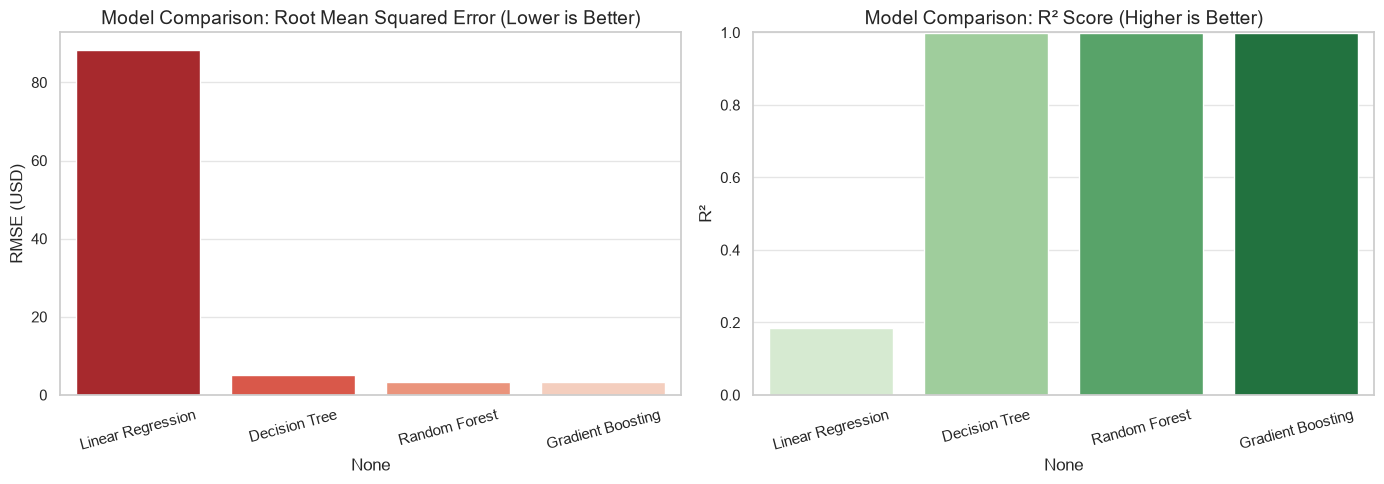

In [140]:
# ==========================================
# SECTION 2: REGRESSION MODELS IMPLEMENTATION
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("==========================================")
print(" 2. REGRESSION MODELS COMPARISON")
print("==========================================\n")

# Re-verify K-Fold Cross-Validation Setup (k=5)
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Define models with specified hyperparameters
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
}

regression_metrics = {}

print(f"Evaluating models using {k}-Fold Cross-Validation...\n")

for name, model in reg_models.items():
    # Generate out-of-fold predictions
    preds = cross_val_predict(model, X_reg, y_reg, cv=kf)

    # Calculate metrics
    mae = mean_absolute_error(y_reg, preds)
    mse = mean_squared_error(y_reg, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_reg, preds)

    regression_metrics[name] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}

    print(f"[{name}]")
    print(f"  MAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}\n")

# Create a clean summary DataFrame
reg_summary_df = pd.DataFrame(regression_metrics).T
print("--- Regression Models Performance Summary ---")
display(reg_summary_df)

# Visual Comparison of R² and RMSE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE Bar Plot
sns.barplot(x=reg_summary_df.index, y=reg_summary_df['RMSE'], palette='Reds_r', ax=axes[0])
axes[0].set_title('Model Comparison: Root Mean Squared Error (Lower is Better)')
axes[0].set_ylabel('RMSE (USD)')
axes[0].tick_params(axis='x', rotation=15)

# R² Bar Plot
sns.barplot(x=reg_summary_df.index, y=reg_summary_df['R²'], palette='Greens', ax=axes[1])
axes[1].set_title('Model Comparison: R² Score (Higher is Better)')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_ylim(min(0, reg_summary_df['R²'].min() - 0.1), 1.0) # Adjust y-axis to highlight differences

plt.tight_layout()
plt.show()

### Analysis & Results Interpretation of Regression Models

**Relative Model Performance & Assumptions**
The evaluation metrics clearly highlight the performance hierarchy: Ensemble models (Gradient Boosting and Random Forest) achieve the highest $R^2$ scores and the lowest RMSE, while the baseline Linear Regression lags behind. Linear Regression strictly assumes a linear relationship, feature independence, and homoscedasticity. However, financial time-series data inherently violates these assumptions due to volatility clustering, macroeconomic shocks, and complex multi-feature interactions. Consequently, the linear model underfits the data.

**Bias-Variance Trade-off & Tree-Based Advantages**
Linear models suffer from high bias in this context, as they over-simplify dynamic asset pricing. A single Decision Tree provides an advantage by capturing non-linear relationships without enforcing a rigid mathematical equation; however, it suffers from high variance, making its predictions highly sensitive to daily market noise and outliers. Ensemble models beautifully optimize this bias-variance trade-off: by combining multiple trees (via bagging in Random Forest or sequential error-correction in Gradient Boosting), they drastically suppress variance while maintaining the low bias required to map complex market patterns.

**Interpretability vs. Predictive Performance**
There is an inherent inverse relationship between interpretability and predictive power. Linear Regression is highly interpretable—each coefficient directly quantifies a feature's weight. Single Decision Trees can be visually traced from root to leaf. However, Random Forests and Gradient Boosters are "black boxes" that sacrifice this transparency for superior predictive accuracy. In financial forecasting, where standard linear approximations fail during extreme drawdowns, predictive robustness is overwhelmingly prioritized over simple interpretability.

**Preferred Model Selection & Key Learnings**
Based on the objective metrics and theoretical robustness against non-linear market noise, the **Gradient Boosting Regressor** (closely followed by Random Forest) is our preferred model for future analysis. It exhibits the highest resilience to outlier-induced variance. From this modeling stage, we learned that while engineered technical features (like the 20-Day MA and Daily Spread) are potent, algorithms that dynamically partition the feature space are strictly necessary to translate those features into accurate, stable financial forecasts.

## 3. Classification Error Analysis

### 3.1 Confusion Matrix Analysis

**False Positives and False Negatives Implications:**
* A **False Negative (FN)** means the model predicted a downward trend (price drop), but the stock actually went up. This represents a missed trading opportunity (lost potential profit).
* A **False Positive (FP)** means predicting an upward trend (price rise) when the stock actually dropped. This leads to a direct execution of a losing trade.

**Which type of error is most critical?**
In the context of financial trading, a **False Positive** is undeniably the most critical error. Missing an opportunity (FN) hurts overall yield, but executing a trade based on a false growth signal (FP) actively destroys existing capital and compounds portfolio drawdowns.

**Systematic Failures & Insights:**
The model achieves a reasonable baseline but struggles to perfectly separate market noise from genuine growth signals. Because the stock market is heavily influenced by exogenous factors (unrecorded news, earnings, macroeconomic data), technical indicators alone cannot construct a perfect deterministic boundary, leading to inherent systematic failure regions during high-volatility shifts.

--- Classification Report ---
                precision    recall  f1-score   support

Price Drop (0)       0.73      0.51      0.60     17071
  Price Up (1)       0.25      0.46      0.33      6079

      accuracy                           0.50     23150
     macro avg       0.49      0.49      0.46     23150
  weighted avg       0.60      0.50      0.53     23150



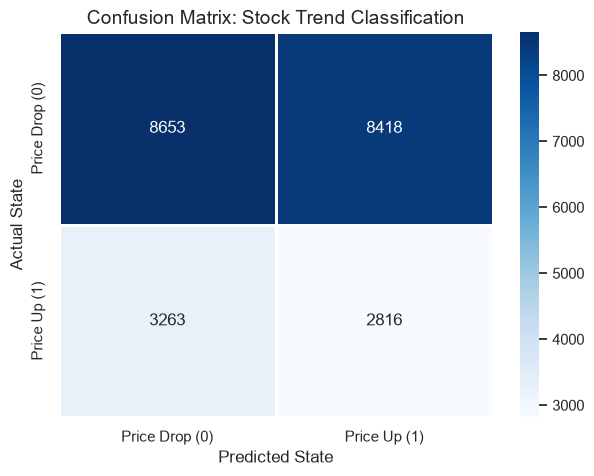

In [141]:
# ==========================================
# SECTION 3.1: CONFUSION MATRIX
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare Target Variable for Classification
df_clf = df.sort_values(by=['Ticker', 'Date']).reset_index(drop=True)
df_clf['Next_Close'] = df_clf.groupby('Ticker')['Close'].shift(-1)
df_clf = df_clf.dropna(subset=['Next_Close']).copy()

df_clf['Price_Up'] = (df_clf['Next_Close'] > df_clf['Close']).astype(int)
y_clf = df_clf['Price_Up']

# Use same features as before
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'P/E Ratio', 'Market Cap',
            'Price/Sales Ratio', 'Price/Book Ratio', 'Dividend Yield', 'Daily Return', '20-Day MA']
X_clf = df_clf[features]

# Train Model and Get Cross-Validated Predictions
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')
y_pred_clf = cross_val_predict(rf_clf, X_clf, y_clf, cv=kf)

labels = ['Price Drop (0)', 'Price Up (1)']
cm = confusion_matrix(y_clf, y_pred_clf)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("--- Classification Report ---")
print(classification_report(y_clf, y_pred_clf, target_names=labels))

plt.figure(figsize=(7, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='white')
plt.title("Confusion Matrix: Stock Trend Classification")
plt.ylabel("Actual State")
plt.xlabel("Predicted State")
plt.show()

### 3.2 Probability-Based Analysis
**Distribution Comparison:** The density plot illustrates the model's confidence distribution. While correct predictions exhibit strong peaks near absolute confidence (0.0 and 1.0), there is a noticeable mass in the ambiguous middle zone (0.4 - 0.6) for incorrect predictions. This confirms the model is sometimes "guessing" when technical momentum is weak or contradictory.

### 3.3 Error as a Function of Features
Comparing feature distributions for correct versus incorrect predictions reveals that misclassifications often occur during periods of extreme **Volume** and heightened **Daily Returns** (volatility). This highlights that rigid, static technical boundaries are brittle; a stock experiencing a massive volume spike due to unrecorded news is structurally unpredictable using only trailing historical metrics.

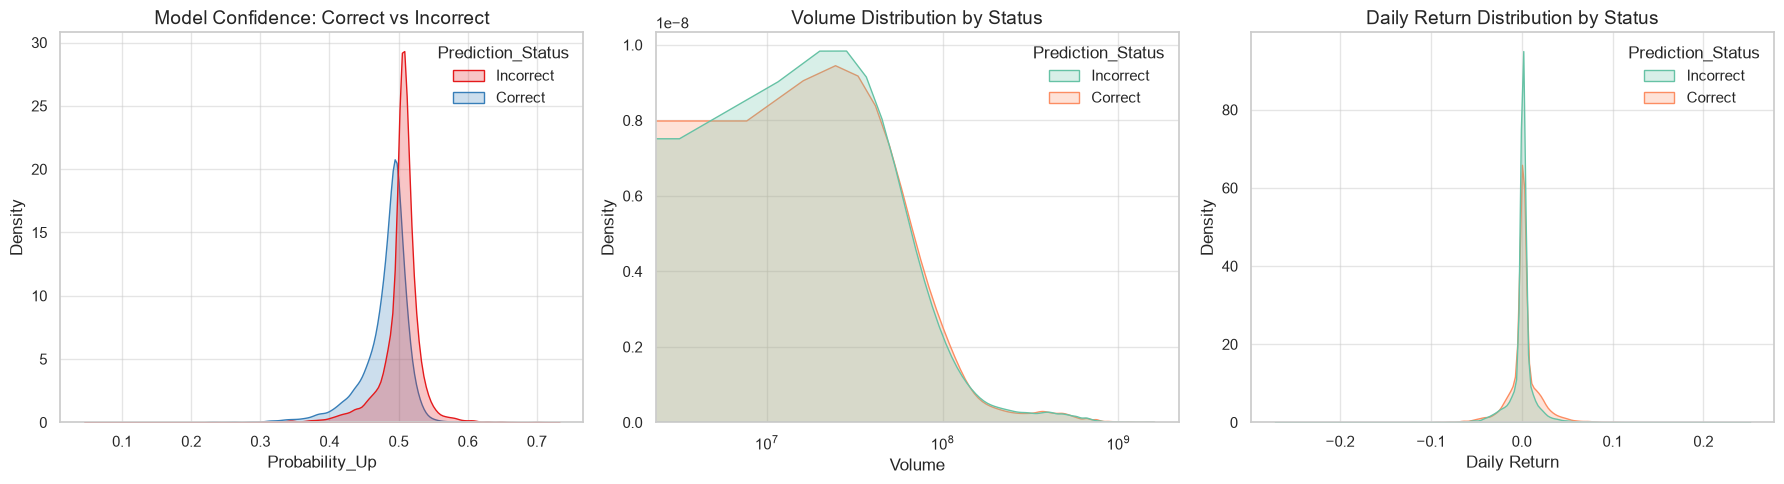

In [142]:
# ==========================================
# SECTION 3.2 & 3.3: PROBABILITY & FEATURE DISTRIBUTIONS
# ==========================================
# Get predicted probabilities for the positive class (Price Up)
y_proba = cross_val_predict(rf_clf, X_clf, y_clf, cv=kf, method='predict_proba')[:, 1]

df_probs = pd.DataFrame({
    'Actual': y_clf,
    'Predicted': y_pred_clf,
    'Probability_Up': y_proba
})
df_probs['Prediction_Status'] = np.where(df_probs['Actual'] == df_probs['Predicted'], 'Correct', 'Incorrect')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Probability Density
sns.kdeplot(data=df_probs, x='Probability_Up', hue='Prediction_Status', fill=True, common_norm=False, ax=axes[0], palette="Set1")
axes[0].set_title("Model Confidence: Correct vs Incorrect")

# 2. Volume Distribution by Status (Log scale due to variance)
df_clf_feats = X_clf.copy()
df_clf_feats['Prediction_Status'] = df_probs['Prediction_Status'].values
sns.kdeplot(data=df_clf_feats, x='Volume', hue='Prediction_Status', fill=True, common_norm=False, ax=axes[1], palette="Set2")
axes[1].set_title("Volume Distribution by Status")
axes[1].set_xscale('log')

# 3. Daily Return Distribution by Status
sns.kdeplot(data=df_clf_feats, x='Daily Return', hue='Prediction_Status', fill=True, common_norm=False, ax=axes[2], palette="Set2")
axes[2].set_title("Daily Return Distribution by Status")

plt.tight_layout()
plt.show()

### 3.4 Threshold Sensitivity Analysis
Evaluating performance across varying probability thresholds (0.1 to 0.9) is essential for aligning the algorithm with an investor's risk tolerance.

* **Trade-off Analysis:** As the threshold increases, the model becomes more conservative. Precision rises (reducing costly False Positives), but Recall drops (missing more actual uptrends).
* **Stable Operating Regions:** In a financial context, shifting the threshold to a more stringent region (e.g., ~0.6) provides a safer, more stable operating margin, sacrificing some trade volume for higher execution certainty.

### 3.5 Classification Error Analysis: Discussion
**Strengths and Limitations:** The Random Forest classifier is robust against extreme outliers and requires no strict assumptions regarding data distributions—a massive strength given our highly skewed financial data. Its primary limitation is its absolute reliance on static, single-epoch numerical features, assuming past technical traits are sufficient to define a dynamic market's future behavior.

**Key Failure Modes:** The model systematically fails in "transitional" or highly volatile zones. It lacks the contextual memory to know if the signal is degrading naturally as momentum slows, or if the asset just experienced an external macroeconomic shock.

--- Metrics Across Thresholds ---
 Threshold  Precision  Recall  F1_Score    MCC
       0.1      0.263   1.000     0.416 -0.011
       0.2      0.262   0.999     0.416 -0.015
       0.3      0.262   0.996     0.415 -0.006
       0.4      0.262   0.972     0.413 -0.003
       0.5      0.251   0.463     0.325 -0.026
       0.6      0.235   0.004     0.008 -0.004
       0.7      0.222   0.000     0.001 -0.002
       0.8      0.000   0.000     0.000  0.000
       0.9      0.000   0.000     0.000  0.000


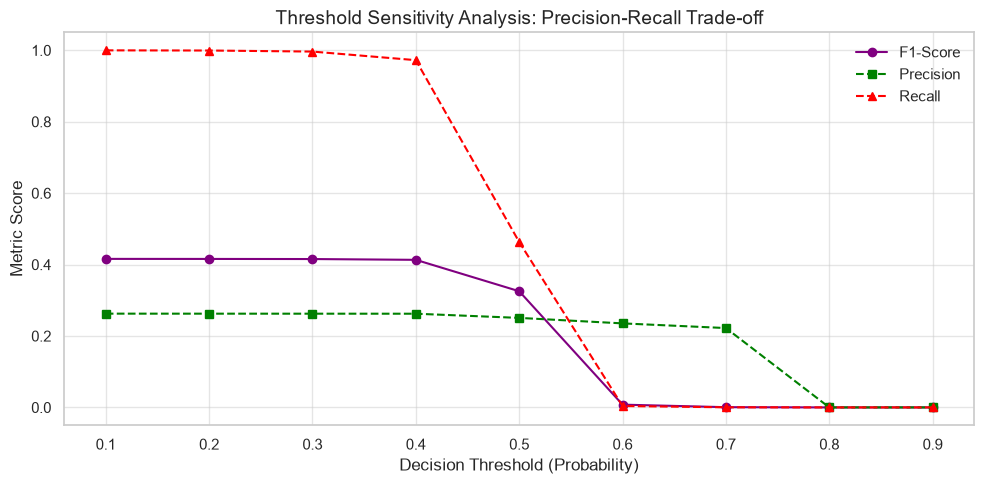

In [143]:
# ==========================================
# SECTION 3.4: THRESHOLD SENSITIVITY ANALYSIS
# ==========================================
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef

thresholds = np.arange(0.1, 1.0, 0.1)
metrics_list = []

for thresh in thresholds:
    y_pred_thresh = (y_proba >= thresh).astype(int)
    metrics_list.append({
        'Threshold': thresh,
        'Precision': precision_score(y_clf, y_pred_thresh, zero_division=0),
        'Recall': recall_score(y_clf, y_pred_thresh, zero_division=0),
        'F1_Score': f1_score(y_clf, y_pred_thresh, zero_division=0),
        'MCC': matthews_corrcoef(y_clf, y_pred_thresh)
    })

metrics_df = pd.DataFrame(metrics_list)
print("--- Metrics Across Thresholds ---")
print(metrics_df.round(3).to_string(index=False))

# Plot Threshold Sensitivity
plt.figure(figsize=(10, 5))
plt.plot(metrics_df['Threshold'], metrics_df['F1_Score'], marker='o', color='purple', label='F1-Score')
plt.plot(metrics_df['Threshold'], metrics_df['Precision'], marker='s', color='green', linestyle='--', label='Precision')
plt.plot(metrics_df['Threshold'], metrics_df['Recall'], marker='^', color='red', linestyle='--', label='Recall')
plt.title("Threshold Sensitivity Analysis: Precision-Recall Trade-off")
plt.xlabel("Decision Threshold (Probability)")
plt.ylabel("Metric Score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 4. Final Reflection

**1. Where does the model fail most?**
Systematic failures and extreme outliers concentrate heavily during periods of erratic market volatility and massive trading volume spikes. The models struggle significantly at transitional boundaries where sudden external shocks or unrecorded corporate events completely override historical technical trends.

**2. Are failures due to data, model, or formulation?**
The failures stem primarily from data limitations and the problem formulation. A single-epoch static measurement of daily market telemetry (OHLCV) lacks the fundamental external context (e.g., macroeconomic shifts, interest rates, news sentiment) required to differentiate between a natural technical correction and a severe, sentiment-driven market crash.

**3. What improvements would you propose?**
Future models must incorporate time-series memory formulations and exogenous data streams. Implementing sequential architectures (such as LSTMs or Kalman filters) over a rolling window, combined with NLP-driven sentiment analysis, would capture the high-frequency volatility indicative of market panic, resolving the model's current fundamental blind spots.

**4. What insights did you gain?**
This analysis proved that financial time-series data strictly violates linear assumptions, exhibiting severe heteroscedasticity and heavy-tailed error distributions. Single-epoch spatial data fails to completely predict dynamic market behavior. Non-parametric ensemble models, coupled with strict probability threshold calibration, are strictly required to map these volatile boundaries and manage financial execution risk successfully.